In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import GRU, Dense, Flatten,Input, Dropout
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from tensorflow.keras.regularizers import l2
from tensorflow.keras import Model
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
from keras.models import load_model

In [3]:
data = pd.read_csv("D:/linthoi/FL_MU.csv")

C:\Users\ranja\AppData\Local\Temp\ipykernel_20308\1550955013.py:1: DtypeWarning: Columns (87) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("D:/linthoi/FL_MU.csv")


In [4]:
data = data.sample(frac=1).reset_index(drop=True)

In [5]:

from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
data['label'] = label_encoder.fit_transform(data['label'])
category_mapping = pd.DataFrame({
    'label': label_encoder.classes_,
    'Encoded Value': label_encoder.transform(label_encoder.classes_)
})

# Display the result
print("Original label and Encoded Values:")
print(category_mapping)


data['category'] = label_encoder.fit_transform(data['category'])
category_mapping = pd.DataFrame({
    'category': label_encoder.classes_,
    'Encoded Value': label_encoder.transform(label_encoder.classes_)
})

# Display the result
print("Original Categories and Encoded Values:")
print(category_mapping)

data['type'] = label_encoder.fit_transform(data['type'])
category_mapping = pd.DataFrame({
    'type': label_encoder.classes_,
    'Encoded Value': label_encoder.transform(label_encoder.classes_)
})

# Display the result
print("Original Categories and Encoded Values:")
print(category_mapping)


Original label and Encoded Values:
    label  Encoded Value
0  Normal              0
1  attack              1
Original Categories and Encoded Values:
               category  Encoded Value
0                  DDOS              0
1                   DoS              1
2                  MiTM              2
3                Normal              3
4  Selective_Forwarding              4
5              Sinkhole              5
6                 Sybil              6
Original Categories and Encoded Values:
                    type  Encoded Value
0             AMQP_flood              0
1          ARP_Poisoning              1
2           DNS_Sinkhole              2
3      DNS_amplification              3
4     MQTT_connect_flood              4
5                 Normal              5
6             SOAP_Flood              6
7            STOMP_Flood              7
8   Selective_Forwarding              8
9                Slowite              9
10                 Sybil             10
11         TCP_SYN

In [6]:
total = len(data)
part_size = total // 3

# Split into 3 parts
part1 = data.iloc[:part_size]
part2 = data.iloc[part_size:2*part_size]
part3 = data.iloc[2*part_size:]


In [17]:
part3.to_csv(r"D:\linthoi\FL_splitted_data\iid_datas\c1.csv", index=False)

In [18]:
part2.to_csv(r"D:\linthoi\FL_splitted_data\iid_datas\c2.csv", index=False)

In [19]:
part1.to_csv(r"D:\linthoi\FL_splitted_data\iid_datas\c3.csv", index=False)

In [ ]:
cl1 = pd.read_csv("D:/linthoi/FL_splitted_data/New/Client1_data.csv")
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
cl1['label'] = label_encoder.fit_transform(cl1['label'])
category_mapping = pd.DataFrame({
    'label': label_encoder.classes_,
    'Encoded Value': label_encoder.transform(label_encoder.classes_)
})

# Display the result
print("Original label and Encoded Values:")
print(category_mapping)


cl1['category'] = label_encoder.fit_transform(cl1['category'])
category_mapping = pd.DataFrame({
    'category': label_encoder.classes_,
    'Encoded Value': label_encoder.transform(label_encoder.classes_)
})

# Display the result
print("Original Categories and Encoded Values:")
print(category_mapping)

cl1['type'] = label_encoder.fit_transform(cl1['type'])
category_mapping = pd.DataFrame({
    'type': label_encoder.classes_,
    'Encoded Value': label_encoder.transform(label_encoder.classes_)
})

# Display the result
print("Original Categories and Encoded Values:")
print(category_mapping)



Original label and Encoded Values:
    label  Encoded Value
0  Normal              0
1  attack              1
Original Categories and Encoded Values:
   category  Encoded Value
0      DDOS              0
1      MiTM              1
2    Normal              2
3  Sinkhole              3
Original Categories and Encoded Values:
            type  Encoded Value
0  ARP_Poisoning              0
1   DNS_Sinkhole              1
2         Normal              2
3     SOAP_Flood              3
4    STOMP_Flood              4


In [21]:
c2=pd.read_csv(r"D:\linthoi\FL_splitted_data\iid_datas\c2.csv")
col_remove = ['SIP', 'DIP', 'SPort', 'DPort', 'SIT', 'STT']         
c2=c2.drop(col_remove, axis=1, inplace=False)
irr_list = []
for i in c2:
    if len(c2[i].unique())<2:
        irr_list.append(i)
c2=c2.drop(irr_list, axis=1, inplace=False)
c2 = c2.dropna(axis=1)


In [22]:
c2

,FPT,LPT,FD,FAMin,FAMean,FAMax,FAStd,FIMean,FIMin,FIMax,...,HTTP_SCUL:,DNSQTL,DNS_QTUL,DNS_RCL,DNS_RCUL,MQTT_MTL,MQTT_MTUL,label,category,type
0,1.725543e+09,1.725543e+09,0.669710,0.669710,0.669710,0.669710,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,1,11
1,1.725543e+09,1.725543e+09,0.737629,0.737629,0.737629,0.737629,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,1,11
2,1.725543e+09,1.725543e+09,0.708378,0.708378,0.708378,0.708378,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,1,11
3,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,1,11
4,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,1,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6264105,1.725539e+09,1.725539e+09,0.000009,0.000009,0.000009,0.000009,0.0,0.0,0.0,0.0,...,0,2,1,0,0,0,0,1,5,2
6264106,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,1,11
6264107,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,1,11
6264108,1.725543e+09,1.725543e+09,0.776843,0.776843,0.776843,0.776843,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,1,11


Change the y1 elements as per the class to be classified

In [3]:
y1 = cl1.iloc[:, -1]

In [12]:
y1.value_counts()

type
2    1002791
0     494815
1     307212
4       2804
3        505
Name: count, dtype: int64

In [3]:
X1=cl1.iloc[:, :-3]
y1 = cl1.iloc[:, -1]
X1 = scaler.fit_transform(X1)
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.3, random_state=42)
#X1_train_r = X1_train.reshape((X1_train.shape[0], 1 , X1_train.shape[1]))
#X1_test_r = X1_test.reshape((X1_test.shape[0], 1 ,X1_test.shape[1]))

In [ ]:
col_remove = ['SIP', 'DIP', 'SPort', 'DPort', 'SIT', 'STT']
fl_mu_data=fl_mu_data.drop(col_remove, axis=1, inplace=False)
irr_list = []
for i in fl_mu_data:
    if len(fl_mu_data[i].unique())<2:
        irr_list.append(i)
fl_mu_data=fl_mu_data.drop(irr_list, axis=1, inplace=False)

Global binary classification model

In [ ]:
#Binary classification model develop by the global server
inputs = Input(shape=(1, 73), name='input_layer')

# GRU layer with 64 units and return sequences set to False
gru_layer1 = GRU(64, name='gru_layer1', kernel_regularizer=l2(0.01), return_sequences=True)(inputs)

# Dropout layer for regularization
dropout_layer = Dropout(0.2, name='dropout_layer')(gru_layer1)

gru_layer2 = GRU(32, name='gru_layer2', kernel_regularizer=l2(0.01), return_sequences=True)(dropout_layer)

# Dropout layer for regularization
dropout_layer2= Dropout(0.2, name='dropout_layer2')(gru_layer2)

gru_layer3 = GRU(16, name='gru_layer3', kernel_regularizer=l2(0.01), return_sequences=True)(dropout_layer2)

# Dropout layer for regularization
dropout_layer3= Dropout(0.2, name='dropout_layer3')(gru_layer3)

flatten_layer = Flatten(name='flatten_layer')(dropout_layer3)
# Dense layer with 1 unit (binary classification) or more (multi-class classification)
output_layer = Dense(2, activation='softmax', name='output_layer',kernel_regularizer=l2(0.01))(flatten_layer)

# Build the model
model_bin = Model(inputs=inputs, outputs=output_layer, name='GRU_Model')

# Compile the model
model_bin.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Model summary to see the structure
model_bin.summary()



Model: "GRU_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 1, 73)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_layer1 (GRU)                │ (None, 1, 64)          │        26,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_layer (Dropout)         │ (None, 1, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_layer2 (GRU)                │ (None, 1, 32)          │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_layer2 (Dropout)        │ (None, 1, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_layer3 (GRU)                │ (None, 1, 16)          │         2,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_layer3 (Dropout)        │ (None, 1, 16)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_layer (Flatten)         │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,530 (150.51 KB)

 Trainable params: 38,530 (150.51 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
G_bin_1=model_bin
# G_bin_2=model_bin
# G_bin_3=model_bin

GLOBAL WEIGHTS AGGREGATION %%%

In [ ]:
# # load_model_C1 = tf.keras.models.load_model("D:/linthoi/FL_models/new/client1_binary_best_weight.keras")
# # WC1=load_model_C1.get_weights()
# # load_model_C2 = tf.keras.models.load_model("D:/linthoi/FL_models/new/client2_binary_best_weight.keras")
# # WC2=load_model_C2.get_weights()
# # load_model_C3 = tf.keras.models.load_model("D:/linthoi/FL_models/new/client3_binary_best_weight.keras")
# # WC3=load_model_C3.get_weights()
# avg_weights = []

# for weights_list_tuple in zip(*weights):
#     avg_weight = tf.reduce_mean(weights_list_tuple, axis=0)
#     avg_weights.append(avg_weight)


In [ ]:
# model_bin.set_weights(avg_weights)
# model_bin.save('D:/linthoi/FL_models/new/1stbin_glob_model.h5')


NOW THE WEIGHTS OF BINARY CLASSIFICATION MODEL IS AGGREGATED

Dont Use this transformer for now

In [ ]:
# # Define a custom transformer that uses the GRU model
# class GRUTransformer:
#     def __init__(self, model_bin):
#         self.model_bin = model_bin
#         #self.fit(self, X, y=None, epochs=3, batch_size=32)
#     def fit(self, X, y=None, epochs= 5, batch_size=32):
#        return self  # No fitting required for GRU model
    
#     def transform(self, X):
#         # Use the GRU model to extract features
#         return self.model_bin.predict(X)
    
    


In [ ]:
# layers_up_to_last = model_bin.layers[:-1]  # Exclude the output layer

# # Create a new model using the layers up to the last layer
# new_model_bin = Model(inputs=model_bin.input, outputs=layers_up_to_last[-1].output, name="GRU_Up_To_Last_Layer_Model")

# model = Pipeline([
#     ('gru_feature_extractor', GRUTransformer(new_model_bin)),  # GRU feature extraction step
#     ('dt_classifier', DecisionTreeClassifier(random_state=42))  # Decision Tree for classification
# ])


Upto this dont use

In [ ]:
# test_loss, test_accuracy = gru_model.evaluate(X_test_r, y_test)

# print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

In [ ]:
# class GRUTransformer(BaseEstimator, TransformerMixin):
#     def __init__(self, gru_model):
#         self.gru_model = gru_model
        
#     def fit(self, X, y=None):
#         # GRU model is not fit; it's pre-trained
#         return self

#     def transform(self, X):
#         # Reshape data to match GRU's input requirements (batch_size, time_steps, features)
#         # Assuming the data is 2D (n_samples, n_features), we add a time step dimension
#         X_reshaped = np.expand_dims(X, axis=1)  # Shape (n_samples, 1, n_features)
#         # Use GRU to transform data to features
#         return self.gru_model.predict(X_reshaped)

In [ ]:
# model['gru_feature_extractor'].get_weights()

In [ ]:
# (model.named_steps['dt_classifier']).feature_importances_
# DecisionTreeClassifier.feature_importances_
# gru_model.get_weights()

For 1st client binary classification

In [11]:
cl1['type'].value_counts()

type
11    4040108
5      250449
1      123955
7         701
6         118
Name: count, dtype: int64

In [3]:
X1=cl1.iloc[:, :-3]
y1 = cl1.iloc[:, -3]
X1 = scaler.fit_transform(X1)
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.3, random_state=42)
X1_train_r = X1_train.reshape((X1_train.shape[0], 1 , X1_train.shape[1]))
X1_test_r = X1_test.reshape((X1_test.shape[0], 1 ,X1_test.shape[1]))

In [13]:
y1.unique()

array([1, 0], dtype=int64)

Dont ################

In [10]:
# G_bin_1.fit(X1_train_r, y1_train) 
# #print('Accuracy score: ', round(accuracy_score(y_test, y_pred), 2))

# y1_pred = G_bin_1.predict(X1_test_r)
# G_bin_1.score(X1_test_r, y1_test)

Do this instead %%%%%%%%%

In [ ]:
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1_binary_best_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)

In [129]:
G_bin_1= model_bin

In [ ]:
G_bin_1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

Epoch 1/5
77266/77269 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9999 - loss: 0.0429
Epoch 1: val_loss did not improve from 0.02878
77269/77269 ━━━━━━━━━━━━━━━━━━━━ 425s 5ms/step - accuracy: 0.9999 - loss: 0.0429 - val_accuracy: 1.0000 - val_loss: 0.0371
Epoch 2/5
77269/77269 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9999 - loss: 0.0380
Epoch 2: val_loss did not improve from 0.02878
77269/77269 ━━━━━━━━━━━━━━━━━━━━ 382s 5ms/step - accuracy: 0.9999 - loss: 0.0380 - val_accuracy: 1.0000 - val_loss: 0.0329
Epoch 3/5
77268/77269 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0350
Epoch 3: val_loss did not improve from 0.02878
77269/77269 ━━━━━━━━━━━━━━━━━━━━ 383s 5ms/step - accuracy: 1.0000 - loss: 0.0350 - val_accuracy: 1.0000 - val_loss: 0.0311
Epoch 4/5
77261/77269 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0330
Epoch 4: val_loss did not improve from 0.02878
77269/77269 ━━━━━━━━━━━━━━━━━━━━ 383s 5ms/step - accuracy: 1.0000 - loss: 0.0330 - val_

In [ ]:
#Checking the saved model above
load_model = tf.keras.models.load_model("D:/linthoi/FL_models/new/client1_binary_best_weight.keras")
load_model.get_weights()

In [ ]:
# USING THE GLOBAL AGGREGATED MODEL WITHOUT TRAINING AGAIN JUST FOR CHECKING
y1_pred = model_bin.predict(X1_test_r)  # Use the model you want (new_model or original model)


41394/41394 ━━━━━━━━━━━━━━━━━━━━ 65s 2ms/step
Accuracy Score: 0.9431888872112336


In [11]:
# yp=[]
# for i in y1_pred:
#     if i > 0.5:
#         yp.append(1)
#     else:
#         yp.append(0)

# # Convert the predictions to class labels (if using softmax output)
# #y1_pred_labels = np.argmax(y1_pred, axis=1)

# # Calculate the accuracy score
# accuracy = accuracy_score(y1_test, y1_pred)
# print(f"Accuracy Score: {accuracy}")


In [122]:
np.unique(y1_pred)

array([0.28085312, 0.28085315, 0.28085318, ..., 0.71914434, 0.7191444 ,
       0.71914446], dtype=float32)

In [ ]:

y1_pred = G_bin_1.predict(X1_test_r)  # Use the model you want (new_model or original model)

# Convert the predictions to class labels (if using softmax output)
y1_pred_labels = np.argmax(y1_pred, axis=1)

# Calculate the accuracy score


41394/41394 ━━━━━━━━━━━━━━━━━━━━ 69s 2ms/step


ValueError: Classification metrics can't handle a mix of binary and continuous-multioutput targets

Accuracy Score: 1.0


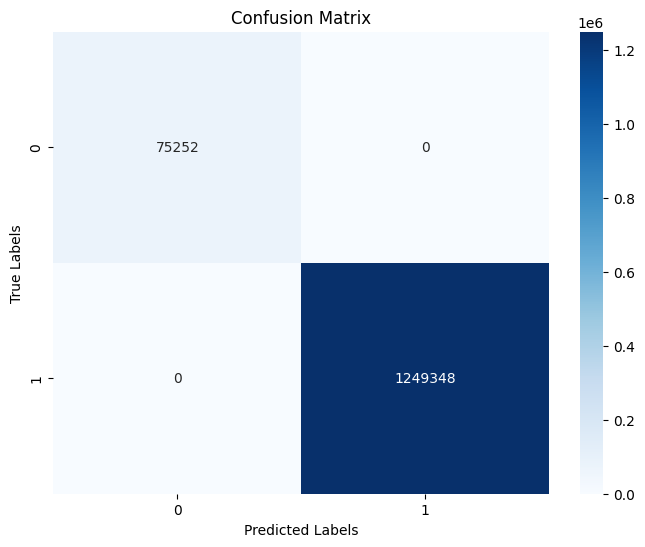

In [132]:
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

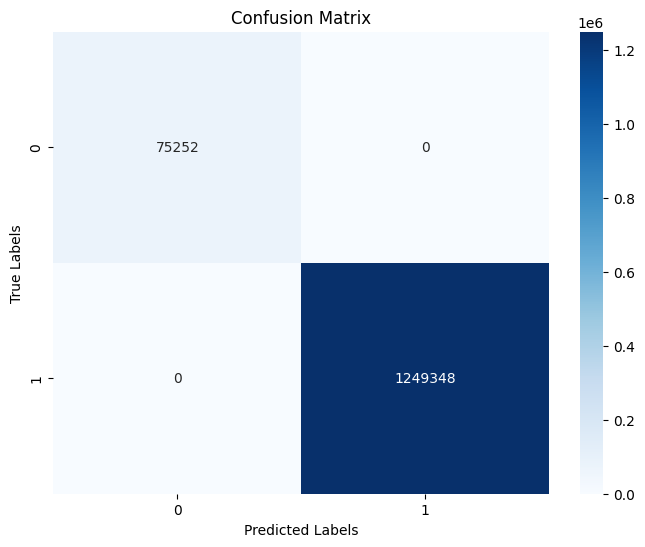

In [33]:
import matplotlib.pyplot as plt
conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

In [7]:
from keras.models import load_model

In [ ]:
updated_model2nd = load_model('D:/linthoi/FL_models/new/2ndbin_glob_model.h5')
updated_model2nd.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [7]:
updated_model2nd.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [8]:
updated_model2nd.get_weights()

[array([[-1.5453117e-05, -4.3941430e-08,  2.8448042e-06, ...,
         -7.5442070e-04,  6.6250082e-06, -1.5616279e-06],
        [-1.4861105e-07, -7.6695706e-08, -5.2906825e-07, ...,
         -8.3497604e-03,  3.9986390e-04, -5.4779152e-06],
        [-6.6401403e-06, -3.4456797e-08, -4.3640571e-06, ...,
         -8.3497595e-03,  3.9986390e-04, -5.4779139e-06],
        ...,
        [-9.0513652e-08, -2.2985716e-06,  2.9008447e-08, ...,
          9.7725412e-04, -5.6145374e-05,  6.1549144e-07],
        [ 6.0273436e-08,  7.9550074e-07, -1.0749691e-07, ...,
          2.3593330e-04, -4.5955098e-06,  3.4607410e-09],
        [ 1.2780851e-08,  4.9269357e-09,  4.5599506e-08, ...,
          9.1888197e-04, -1.7376538e-05,  7.9462303e-08]], dtype=float32),
 array([[ 0.06120588, -0.05009326,  0.05515286, ...,  0.0048919 ,
         -0.06567136,  0.04619128],
        [-0.00588059,  0.02698278, -0.04467542, ...,  0.01260482,
         -0.02690624,  0.02006933],
        [ 0.00032224, -0.02555242, -0.00560162

In [142]:
updated_model.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback])

Epoch 1/5
77262/77269 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9994 - loss: 0.0472
Epoch 1: val_loss did not improve from 0.02827
77269/77269 ━━━━━━━━━━━━━━━━━━━━ 398s 5ms/step - accuracy: 0.9994 - loss: 0.0472 - val_accuracy: 1.0000 - val_loss: 0.0365
Epoch 2/5
77265/77269 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0377
Epoch 2: val_loss did not improve from 0.02827
77269/77269 ━━━━━━━━━━━━━━━━━━━━ 394s 5ms/step - accuracy: 1.0000 - loss: 0.0377 - val_accuracy: 1.0000 - val_loss: 0.0323
Epoch 3/5
77267/77269 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0342
Epoch 3: val_loss did not improve from 0.02827
77269/77269 ━━━━━━━━━━━━━━━━━━━━ 398s 5ms/step - accuracy: 1.0000 - loss: 0.0342 - val_accuracy: 1.0000 - val_loss: 0.0301
Epoch 4/5
77265/77269 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 0.0319
Epoch 4: val_loss did not improve from 0.02827
77269/77269 ━━━━━━━━━━━━━━━━━━━━ 360s 5ms/step - accuracy: 1.0000 - loss: 0.0319 - val_

41394/41394 ━━━━━━━━━━━━━━━━━━━━ 44s 1ms/step
Accuracy Score: 0.9431888872112336


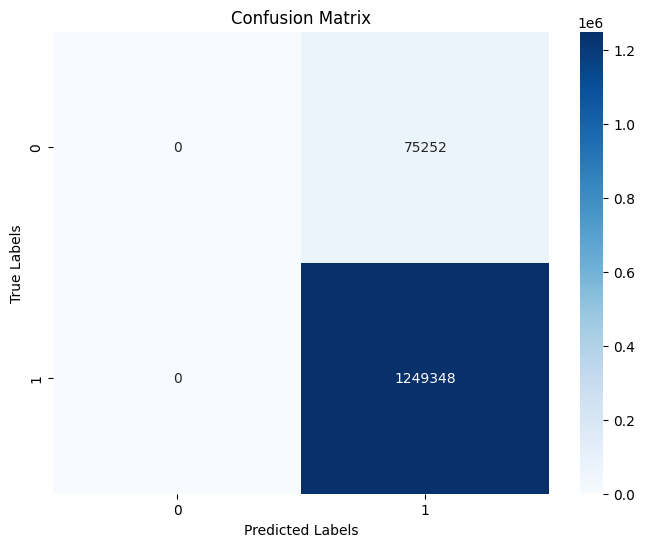

In [9]:
y1_pred = updated_model2nd.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

In [137]:
y1_pred = updated_model.predict(X1_test_r) 

41394/41394 ━━━━━━━━━━━━━━━━━━━━ 67s 2ms/step


In [138]:
y1_pred_labels = np.argmax(y1_pred, axis=1)

Accuracy Score: 0.9431888872112336


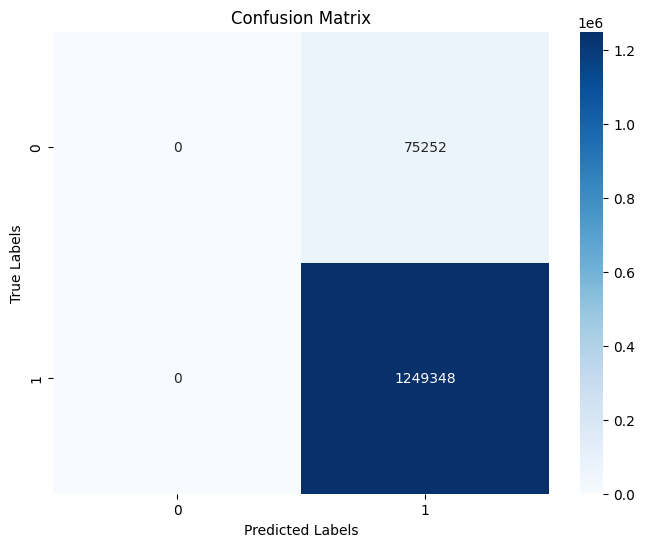

In [139]:
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

Multiclass classification for category with 4 classes however the cells below need not run again

In [4]:
cl1['label'] = label_encoder.fit_transform(cl1['label'])
category_mapping = pd.DataFrame({
    'label': label_encoder.classes_,
    'Encoded Value': label_encoder.transform(label_encoder.classes_)
})

# Display the result
print("Original label and Encoded Values:")
print(category_mapping)

Original label and Encoded Values:
    label  Encoded Value
0  Normal              0
1  attack              1


In [5]:

cl1['category'] = label_encoder.fit_transform(cl1['category'])
category_mapping = pd.DataFrame({
    'category': label_encoder.classes_,
    'Encoded Value': label_encoder.transform(label_encoder.classes_)
})

# Display the result
print("Original Categories and Encoded Values:")
print(category_mapping)

Original Categories and Encoded Values:
   category  Encoded Value
0      DDOS              0
1      MiTM              1
2    Normal              2
3  Sinkhole              3


In [6]:
cl1['type'] = label_encoder.fit_transform(cl1['type'])
category_mapping = pd.DataFrame({
    'type': label_encoder.classes_,
    'Encoded Value': label_encoder.transform(label_encoder.classes_)
})

# Display the result
print("Original Categories and Encoded Values:")
print(category_mapping)

Original Categories and Encoded Values:
            type  Encoded Value
0  ARP_Poisoning              0
1   DNS_Sinkhole              1
2         Normal              2
3     SOAP_Flood              3
4    STOMP_Flood              4


In [7]:
X1=cl1.iloc[:, :-3]
y1 = cl1.iloc[:, -2]
X1 = scaler.fit_transform(X1)
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.3, random_state=42)
X1_train_r = X1_train.reshape((X1_train.shape[0], 1 , X1_train.shape[1]))
X1_test_r = X1_test.reshape((X1_test.shape[0], 1 ,X1_test.shape[1]))

In [21]:
y1_test.value_counts()

category
2    300185
1    148776
3     92518
0       960
Name: count, dtype: int64

In [20]:
y1.value_counts()

category
2    1002791
1     494815
3     307212
0       3309
Name: count, dtype: int64

In [15]:
cl1['category'].unique()

array([2, 3, 1, 0])

In [13]:
cl1['type'].unique()

array([11,  5,  1,  7,  6], dtype=int64)

In [ ]:
#
model_cate = load_model('D:/linthoi/FL_models/new/Cate_glob_model.h5')
model_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1_cate_best_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)

In [ ]:
#from tensorflow.keras.callbacks import ModelCheckpoint


In [25]:
model_cate.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

Epoch 1/10
31637/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9830 - loss: 0.3830
Epoch 1: val_loss improved from inf to 0.24120, saving model to D:/linthoi/FL_models/new/client1_cate_best_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 88s 3ms/step - accuracy: 0.9830 - loss: 0.3830 - val_accuracy: 0.9982 - val_loss: 0.2412
Epoch 2/10
31639/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9978 - loss: 0.2401
Epoch 2: val_loss improved from 0.24120 to 0.19381, saving model to D:/linthoi/FL_models/new/client1_cate_best_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 86s 3ms/step - accuracy: 0.9978 - loss: 0.2401 - val_accuracy: 0.9982 - val_loss: 0.1938
Epoch 3/10
31639/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9979 - loss: 0.1965
Epoch 3: val_loss improved from 0.19381 to 0.16821, saving model to D:/linthoi/FL_models/new/client1_cate_best_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 85s 3ms/step - accuracy: 0.9979 - loss: 0.1965 - val_accuracy: 0.9981 - val_loss: 0.1

16952/16952 ━━━━━━━━━━━━━━━━━━━━ 24s 1ms/step
Accuracy Score: 0.998226528697236


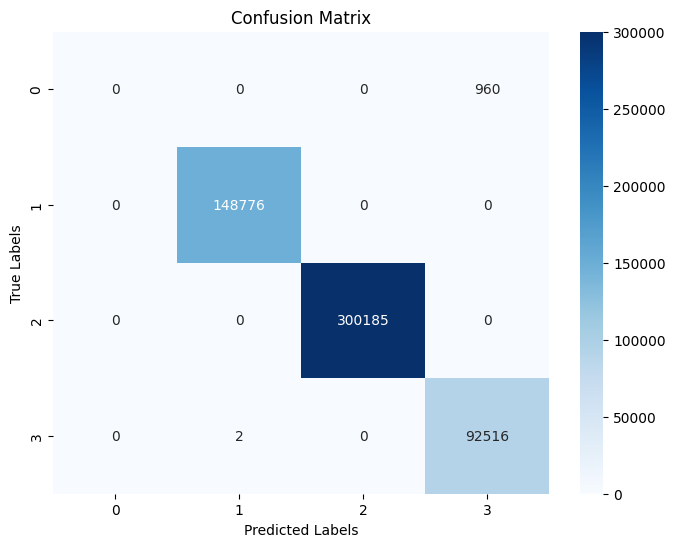

In [ ]:
y1_pred = model_cate.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 4 class classification before fl: {accuracy:.4f}")
print(f"Precision for 4 class classification before fl: {precision:.4f}")
print(f"Recall for 4 class classification before fl: {recall:.4f}")
print(f"F1 Score for 4 class classification before fl: {f1:.4f}")
print(f"MCC for 4 class classification before fl: {mcc:.4f}")

In [ ]:
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 4 class classification before fl: {accuracy:.4f}")
print(f"Precision for 4 class classification before fl: {precision:.4f}")
print(f"Recall for 4 class classification before fl: {recall:.4f}")
print(f"F1 Score for 4 class classification before fl: {f1:.4f}")
print(f"MCC for 4 class classification before fl: {mcc:.4f}")

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Accuracy for 4 class classification before fl: 0.9982
Precision for 4 class classification before fl: 0.7474
Recall for 4 class classification before fl: 0.7500
F1 Score for 4 class classification before fl: 0.7487
MCC for 4 class classification before fl: 0.9970


In [29]:
load_model_C1 = tf.keras.models.load_model("D:/linthoi/FL_models/new/client2_cate_best_weight.keras")

1st fl round for category classification using the updated model

In [17]:
model_cate_bfl = load_model('D:/linthoi/FL_models/new/client1_cate_best_weight.keras')
#D:\linthoi\FL_models\new

In [18]:
model_cate_bfl.get_weights()

[array([[ 1.21057120e-08,  2.16299486e-05, -2.46922609e-05, ...,
          2.47243634e-06, -1.07399268e-04, -3.02303470e-05],
        [-1.62732846e-07,  2.16299341e-05, -2.46896379e-05, ...,
          2.47243611e-06, -1.07399203e-04, -3.02303524e-05],
        [-5.60810633e-07,  4.62041353e-05, -3.57777790e-05, ...,
          4.90499406e-06, -8.10599595e-05, -4.26100178e-06],
        ...,
        [-1.18049996e-08,  6.59097668e-06, -2.36045844e-06, ...,
         -1.53496046e-07,  1.22157053e-05,  4.34926460e-06],
        [ 3.47324480e-09, -5.62988862e-05, -5.16850832e-06, ...,
         -4.39532215e-08,  1.03434031e-05,  1.15711759e-06],
        [ 1.13334345e-05, -1.09074754e-05, -3.59678415e-06, ...,
         -3.53933387e-07, -1.00991165e-05, -3.34378342e-07]], dtype=float32),
 array([[ 0.02949429,  0.09929313, -0.10583674, ...,  0.01996378,
         -0.01320487,  0.05570147],
        [-0.07596169,  0.08029008, -0.07850148, ...,  0.11750399,
          0.03812586,  0.02100072],
        [-

In [19]:
model_cate.get_weights()

[array([[ 3.3303018e-05, -4.5464890e-06,  3.7823806e-06, ...,
         -2.2940689e-03,  1.2207600e-05, -3.2530923e-05],
        [ 1.0643724e-05, -4.5464039e-06,  3.7823365e-06, ...,
         -2.2940682e-03,  1.2207602e-05, -3.2530919e-05],
        [-1.4872903e-06, -1.9951008e-06, -3.7371415e-06, ...,
          3.7489790e-03,  1.4371821e-05,  1.5150589e-05],
        ...,
        [-3.0053748e-08,  2.8897769e-06,  4.5848432e-07, ...,
          1.5278297e-04, -6.5072754e-08, -7.4089808e-06],
        [ 1.6985942e-09,  1.8708155e-05,  4.1140169e-07, ...,
         -1.4695310e-04,  1.5798634e-08,  5.1186379e-07],
        [-2.4750977e-09,  2.0742470e-07, -1.1936486e-07, ...,
         -4.7621568e-04, -4.4452224e-07, -1.8857282e-06]], dtype=float32),
 array([[ 0.02949429,  0.09929314, -0.10583674, ...,  0.01996378,
         -0.01320487,  0.05570148],
        [-0.07596169,  0.08029008, -0.07850148, ...,  0.11750399,
          0.03812586,  0.02100072],
        [-0.00711831,  0.09585825,  0.11256683

In [ ]:
model_cate = load_model('D:/linthoi/FL_models/new/1st_round_cate_glob_model.h5')
model_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1_cate_after_1stround_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
model_cate.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

In [6]:
model_cate.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

Epoch 1/10
31633/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9924 - loss: 0.1621
Epoch 1: val_loss improved from inf to 0.10813, saving model to D:/linthoi/FL_models/new/client1_cate_after_1stround_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 92s 3ms/step - accuracy: 0.9924 - loss: 0.1621 - val_accuracy: 0.9981 - val_loss: 0.1081
Epoch 2/10
31632/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9962 - loss: 0.1233
Epoch 2: val_loss improved from 0.10813 to 0.10441, saving model to D:/linthoi/FL_models/new/client1_cate_after_1stround_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 98s 3ms/step - accuracy: 0.9962 - loss: 0.1233 - val_accuracy: 0.9982 - val_loss: 0.1044
Epoch 3/10
31630/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9961 - loss: 0.1203
Epoch 3: val_loss improved from 0.10441 to 0.10251, saving model to D:/linthoi/FL_models/new/client1_cate_after_1stround_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 98s 3ms/step - accuracy: 0.9961 - loss: 0.1203 - val_ac

16952/16952 ━━━━━━━━━━━━━━━━━━━━ 20s 1ms/step
Accuracy Score: 0.9982302157477615


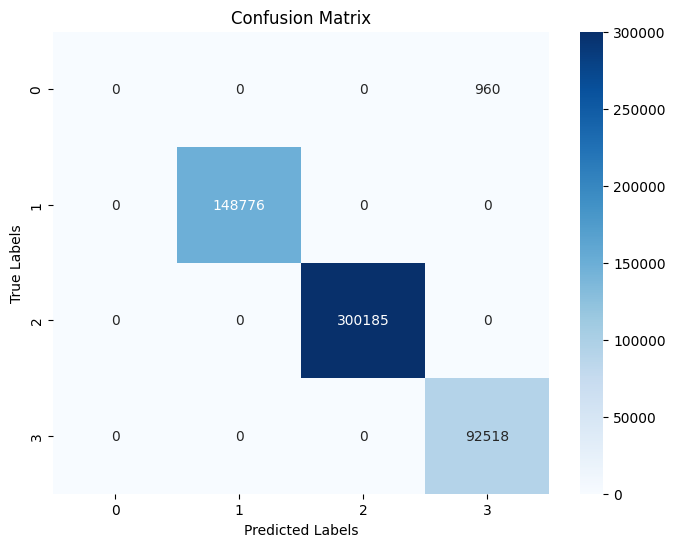

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Accuracy for 4 class classification 1st round fl: 0.9982
Precision for 4 class classification 1st round fl: 0.7474
Recall for 4 class classification 1st round fl: 0.7500
F1 Score for 4 class classification 1st round fl: 0.7487
MCC for 4 class classification 1st round fl: 0.9970


In [7]:
y1_pred = model_cate.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 4 class classification 1st round fl: {accuracy:.4f}")
print(f"Precision for 4 class classification 1st round fl: {precision:.4f}")
print(f"Recall for 4 class classification 1st round fl: {recall:.4f}")
print(f"F1 Score for 4 class classification 1st round fl: {f1:.4f}")
print(f"MCC for 4 class classification 1st round fl: {mcc:.4f}")

2nd round fl round for category classification using the updated model

In [8]:
model_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/2nd_round_cate_glob_model.h5')
model_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/category/client1_cate_2ndround_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
model_cate.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

Epoch 1/10
31630/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9943 - loss: 0.1097
Epoch 1: val_loss improved from inf to 0.09036, saving model to D:/linthoi/FL_models/new/client1/category/client1_cate_2ndround_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 87s 3ms/step - accuracy: 0.9943 - loss: 0.1097 - val_accuracy: 0.9982 - val_loss: 0.0904
Epoch 2/10
31631/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9962 - loss: 0.0985
Epoch 2: val_loss improved from 0.09036 to 0.08330, saving model to D:/linthoi/FL_models/new/client1/category/client1_cate_2ndround_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 90s 3ms/step - accuracy: 0.9962 - loss: 0.0985 - val_accuracy: 0.9982 - val_loss: 0.0833
Epoch 3/10
31636/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9960 - loss: 0.0982
Epoch 3: val_loss improved from 0.08330 to 0.08238, saving model to D:/linthoi/FL_models/new/client1/category/client1_cate_2ndround_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 96s 3ms/step - accurac

16952/16952 ━━━━━━━━━━━━━━━━━━━━ 25s 1ms/step
Accuracy Score: 0.9982302157477615


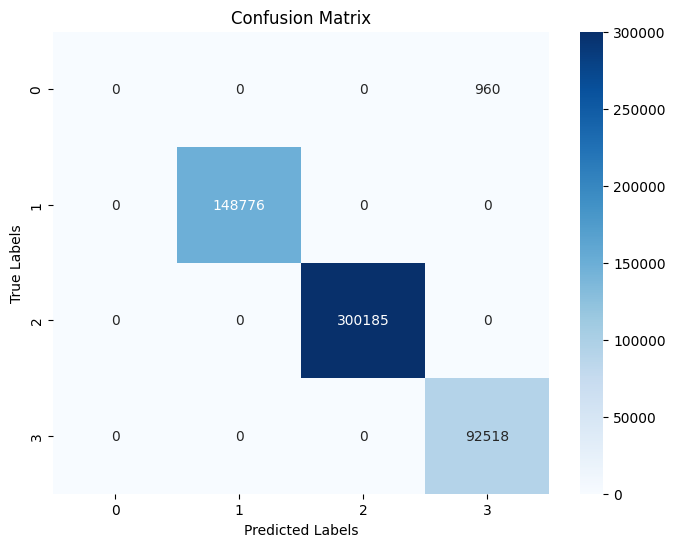

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Accuracy for 4 class classification 2nd round fl: 0.9982
Precision for 4 class classification 2nd round fl: 0.7474
Recall for 4 class classification 2nd round fl: 0.7500
F1 Score for 4 class classification 2nd round fl: 0.7487
MCC for 4 class classification 2nd round fl: 0.9970


In [9]:
y1_pred = model_cate.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 4 class classification 2nd round fl: {accuracy:.4f}")
print(f"Precision for 4 class classification 2nd round fl: {precision:.4f}")
print(f"Recall for 4 class classification 2nd round fl: {recall:.4f}")
print(f"F1 Score for 4 class classification 2nd round fl: {f1:.4f}")
print(f"MCC for 4 class classification 2nd round fl: {mcc:.4f}")

3rd round fl categorical classification

In [5]:
model_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/3rd_round_cate_glob_model.h5')
model_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/category/client1_cate_3rdround_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
model_cate.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

Epoch 1/10
31642/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9956 - loss: 0.0938
Epoch 1: val_loss improved from inf to 0.07602, saving model to D:/linthoi/FL_models/new/client1/category/client1_cate_3rdround_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 82s 2ms/step - accuracy: 0.9956 - loss: 0.0938 - val_accuracy: 0.9982 - val_loss: 0.0760
Epoch 2/10
31632/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9962 - loss: 0.0895
Epoch 2: val_loss improved from 0.07602 to 0.07443, saving model to D:/linthoi/FL_models/new/client1/category/client1_cate_3rdround_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 77s 2ms/step - accuracy: 0.9962 - loss: 0.0895 - val_accuracy: 0.9982 - val_loss: 0.0744
Epoch 3/10
31630/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9962 - loss: 0.0892
Epoch 3: val_loss did not improve from 0.07443
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 84s 3ms/step - accuracy: 0.9962 - loss: 0.0892 - val_accuracy: 0.9982 - val_loss: 0.0756
Epoch 4/10
31640/31643 ━━━━━━━━

16952/16952 ━━━━━━━━━━━━━━━━━━━━ 23s 1ms/step
Accuracy Score: 0.9982302157477615


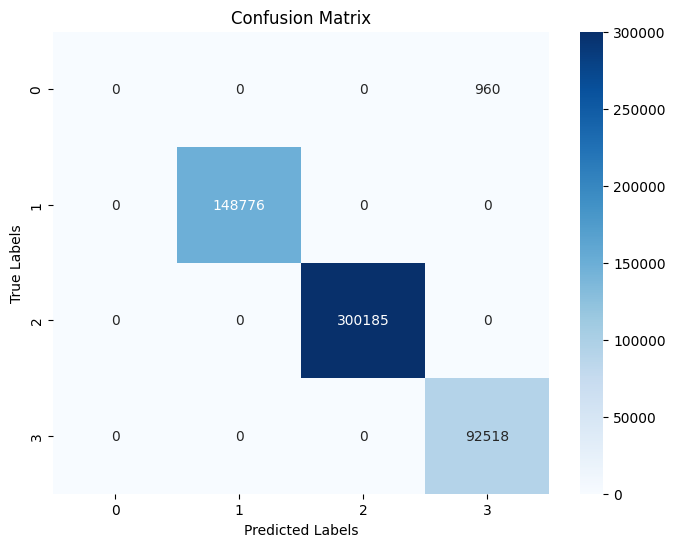

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Accuracy for 4 class classification 3rd round fl: 0.9982
Precision for 4 class classification 3rd round fl: 0.7474
Recall for 4 class classification 3rd round fl: 0.7500
F1 Score for 4 class classification 3rd round fl: 0.7487
MCC for 4 class classification 3rd round fl: 0.9970


In [6]:
y1_pred = model_cate.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 4 class classification 3rd round fl: {accuracy:.4f}")
print(f"Precision for 4 class classification 3rd round fl: {precision:.4f}")
print(f"Recall for 4 class classification 3rd round fl: {recall:.4f}")
print(f"F1 Score for 4 class classification 3rd round fl: {f1:.4f}")
print(f"MCC for 4 class classification 3rd round fl: {mcc:.4f}")

5 class type multiclass classification before FL

In [8]:
ini_model = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/firstinitialized/Type_glob_model.h5')
ini_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [9]:
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_type_bforeFL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
ini_model.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

Epoch 1/10
31618/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9754 - loss: 0.4052
Epoch 1: val_loss improved from inf to 0.24112, saving model to D:/linthoi/FL_models/new/client1/type/client1_type_bforeFL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 89s 3ms/step - accuracy: 0.9754 - loss: 0.4052 - val_accuracy: 0.9981 - val_loss: 0.2411
Epoch 2/10
31634/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9977 - loss: 0.2418
Epoch 2: val_loss improved from 0.24112 to 0.19092, saving model to D:/linthoi/FL_models/new/client1/type/client1_type_bforeFL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 80s 3ms/step - accuracy: 0.9977 - loss: 0.2418 - val_accuracy: 0.9982 - val_loss: 0.1909
Epoch 3/10
31627/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9978 - loss: 0.1990
Epoch 3: val_loss improved from 0.19092 to 0.16999, saving model to D:/linthoi/FL_models/new/client1/type/client1_type_bforeFL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 85s 3ms/step - accuracy: 0.9978 - los

16952/16952 ━━━━━━━━━━━━━━━━━━━━ 27s 2ms/step
Accuracy Score: 0.9982302157477615


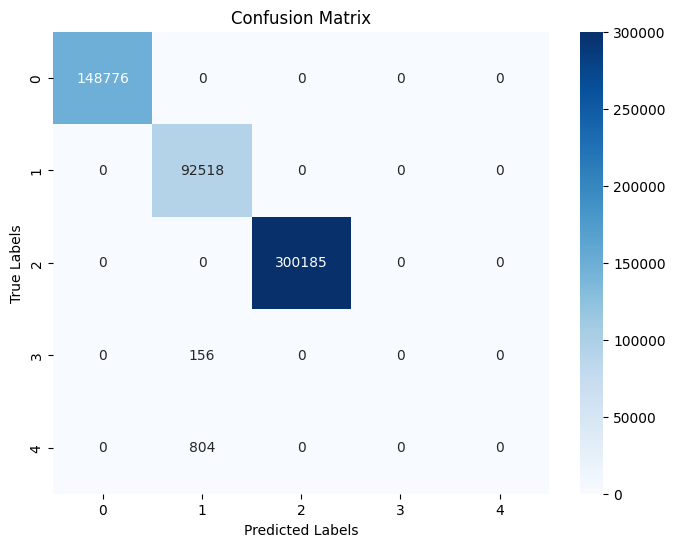

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Accuracy for 4 class classification bfore fl: 0.9982
Precision for 4 class classification bfore fl: 0.5979
Recall for 4 class classification bfore fl: 0.6000
F1 Score for 4 class classification bfore fl: 0.5990
MCC for 4 class classification bfore fl: 0.9970


In [10]:
y1_pred = ini_model.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 4 class classification bfore fl: {accuracy:.4f}")
print(f"Precision for 4 class classification bfore fl: {precision:.4f}")
print(f"Recall for 4 class classification bfore fl: {recall:.4f}")
print(f"F1 Score for 4 class classification bfore fl: {f1:.4f}")
print(f"MCC for 4 class classification bfore fl: {mcc:.4f}")

5 class multiclass classification 1st FL round (type)

Epoch 1/10
31640/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9874 - loss: 0.1995
Epoch 1: val_loss improved from inf to 0.12817, saving model to D:/linthoi/FL_models/new/client1/type/client1_type_1st_round_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 101s 3ms/step - accuracy: 0.9874 - loss: 0.1995 - val_accuracy: 0.9982 - val_loss: 0.1282
Epoch 2/10
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9964 - loss: 0.1436
Epoch 2: val_loss improved from 0.12817 to 0.12244, saving model to D:/linthoi/FL_models/new/client1/type/client1_type_1st_round_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 96s 3ms/step - accuracy: 0.9964 - loss: 0.1436 - val_accuracy: 0.9982 - val_loss: 0.1224
Epoch 3/10
31631/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9963 - loss: 0.1375
Epoch 3: val_loss did not improve from 0.12244
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 101s 3ms/step - accuracy: 0.9963 - loss: 0.1375 - val_accuracy: 0.9982 - val_loss: 0.1227
Epoch 4/10
31633/31643 ━━━━━━

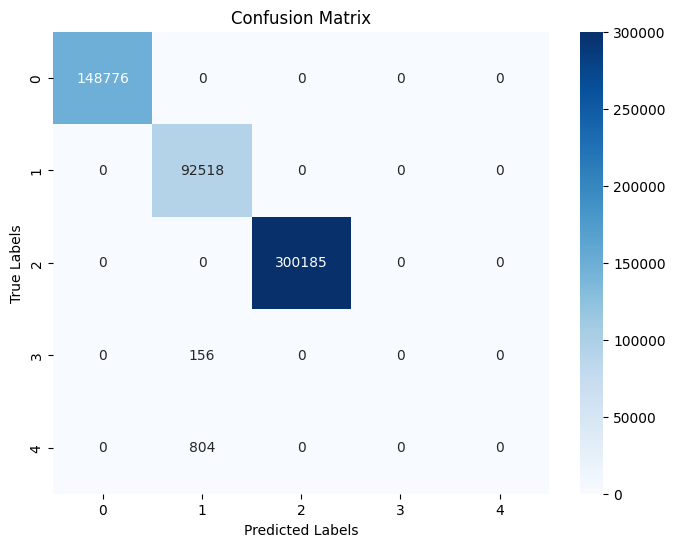

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Accuracy for 5 class classification 1st_round fl: 0.9982
Precision for 5 class classification 1st_round fl: 0.5979
Recall for 5 class classification 1st_round fl: 0.6000
F1 Score for 5 class classification 1st_round fl: 0.5990
MCC for 5 class classification 1st_round fl: 0.9970


In [12]:
model_type1 = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/1st_round_type_glob_model.h5')
model_type1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_type_1st_round_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
model_type1.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])
y1_pred = model_type1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 5 class classification 1st_round fl: {accuracy:.4f}")
print(f"Precision for 5 class classification 1st_round fl: {precision:.4f}")
print(f"Recall for 5 class classification 1st_round fl: {recall:.4f}")
print(f"F1 Score for 5 class classification 1st_round fl: {f1:.4f}")
print(f"MCC for 5 class classification 1st_round fl: {mcc:.4f}")

In [13]:
# Print the results
print(f"Accuracy for 5 class classification 1st_round fl: {accuracy:.4f}")
print(f"Precision for 5 class classification 1st_round fl: {precision:.4f}")
print(f"Recall for 5 class classification 1st_round fl: {recall:.4f}")
print(f"F1 Score for 5 class classification 1st_round fl: {f1:.4f}")
print(f"MCC for 5 class classification 1st_round fl: {mcc:.4f}")

Accuracy for 5 class classification 1st_round fl: 0.9982
Precision for 5 class classification 1st_round fl: 0.5979
Recall for 5 class classification 1st_round fl: 0.6000
F1 Score for 5 class classification 1st_round fl: 0.5990
MCC for 5 class classification 1st_round fl: 0.9970


2nd fl round 5 class multiclass classification (type)

Epoch 1/10
31626/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9868 - loss: 0.1602
Epoch 1: val_loss improved from inf to 0.10722, saving model to D:/linthoi/FL_models/new/client1/type/client1_type_2nd_round_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 117s 3ms/step - accuracy: 0.9868 - loss: 0.1602 - val_accuracy: 0.9982 - val_loss: 0.1072
Epoch 2/10
31627/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9962 - loss: 0.1227
Epoch 2: val_loss did not improve from 0.10722
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 109s 3ms/step - accuracy: 0.9962 - loss: 0.1227 - val_accuracy: 0.9982 - val_loss: 0.1100
Epoch 3/10
31629/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9962 - loss: 0.1201
Epoch 3: val_loss improved from 0.10722 to 0.10184, saving model to D:/linthoi/FL_models/new/client1/type/client1_type_2nd_round_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 112s 4ms/step - accuracy: 0.9962 - loss: 0.1201 - val_accuracy: 0.9982 - val_loss: 0.1018
Epoch 4/10
31642/31643 ━━━━━

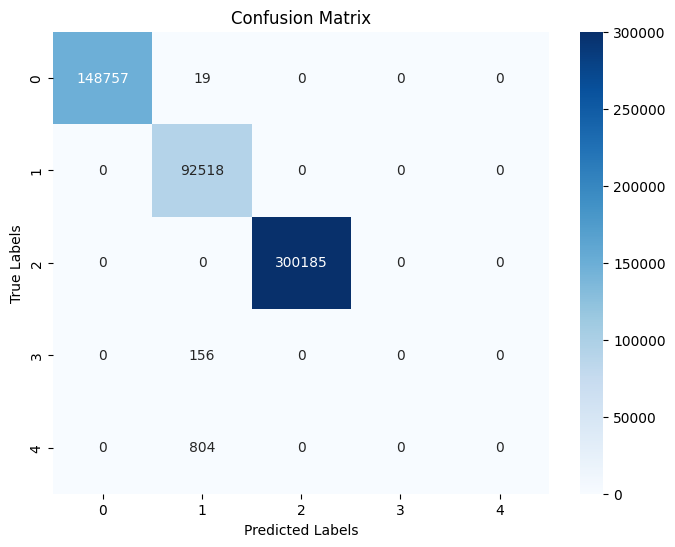

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [45]:
model_type1 = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/2nd_round_type_glob_model.h5')
model_type1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_type_2nd_round_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
model_type1.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])
y1_pred = model_type1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results


In [46]:
print(f"Accuracy for 5 class classification 2nd_round fl: {accuracy:.4f}")
print(f"Precision for 5 class classification 2nd_round fl: {precision:.4f}")
print(f"Recall for 5 class classification 2nd_round fl: {recall:.4f}")
print(f"F1 Score for 5 class classification 2nd_round fl: {f1:.4f}")
print(f"MCC for 5 class classification 2nd_round fl: {mcc:.4f}")

Accuracy for 5 class classification 2nd_round fl: 0.9982
Precision for 5 class classification 2nd_round fl: 0.5979
Recall for 5 class classification 2nd_round fl: 0.6000
F1 Score for 5 class classification 2nd_round fl: 0.5989
MCC for 5 class classification 2nd_round fl: 0.9969


3rd round (type)

Epoch 1/5
31636/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9926 - loss: 0.1200
Epoch 1: val_loss improved from inf to 0.08856, saving model to D:/linthoi/FL_models/new/client1/type/client1_type_3rd_round_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 100s 3ms/step - accuracy: 0.9926 - loss: 0.1200 - val_accuracy: 0.9982 - val_loss: 0.0886
Epoch 2/5
31637/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9961 - loss: 0.1026
Epoch 2: val_loss improved from 0.08856 to 0.08591, saving model to D:/linthoi/FL_models/new/client1/type/client1_type_3rd_round_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 108s 3ms/step - accuracy: 0.9961 - loss: 0.1026 - val_accuracy: 0.9982 - val_loss: 0.0859
Epoch 3/5
31631/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9963 - loss: 0.1014
Epoch 3: val_loss did not improve from 0.08591
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 107s 3ms/step - accuracy: 0.9963 - loss: 0.1014 - val_accuracy: 0.9981 - val_loss: 0.0896
Epoch 4/5
31632/31643 ━━━━━━━━━

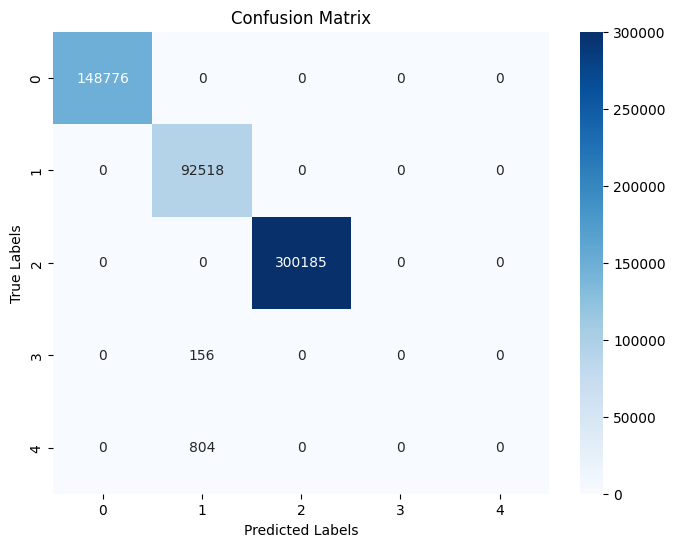

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [48]:
model_type1 = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/3rd_round_type_glob_model.h5')
model_type1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_type_3rd_round_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
model_type1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])
y1_pred = model_type1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results


In [49]:
print(f"Accuracy for 5 class classification 3rd_round fl: {accuracy:.4f}")
print(f"Precision for 5 class classification 3rd_round fl: {precision:.4f}")
print(f"Recall for 5 class classification 3rd_round fl: {recall:.4f}")
print(f"F1 Score for 5 class classification 3rd_round fl: {f1:.4f}")
print(f"MCC for 5 class classification 3rd_round fl: {mcc:.4f}")

Accuracy for 5 class classification 3rd_round fl: 0.9982
Precision for 5 class classification 3rd_round fl: 0.5979
Recall for 5 class classification 3rd_round fl: 0.6000
F1 Score for 5 class classification 3rd_round fl: 0.5990
MCC for 5 class classification 3rd_round fl: 0.9970


CNN_GRU from MDPI

In [7]:
cnn_gru_mdpi = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/firstinitialized/CNN_GRU_MDPI_Type_glob_model.h5')
cnn_gru_mdpi.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [8]:
y1_train.unique()

array([2, 0, 1, 4, 3])

Epoch 1/5
31633/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9941 - loss: 0.0176
Epoch 1: val_loss improved from inf to 0.00010, saving model to D:/linthoi/FL_models/new/client1/type/client1_cnn_gru_mdpi_type_bfore_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 99s 3ms/step - accuracy: 0.9941 - loss: 0.0176 - val_accuracy: 1.0000 - val_loss: 1.0097e-04
Epoch 2/5
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9998 - loss: 9.6134e-04
Epoch 2: val_loss did not improve from 0.00010
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 97s 3ms/step - accuracy: 0.9998 - loss: 9.6132e-04 - val_accuracy: 1.0000 - val_loss: 1.4095e-04
Epoch 3/5
31642/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9999 - loss: 6.2321e-04
Epoch 3: val_loss did not improve from 0.00010
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 98s 3ms/step - accuracy: 0.9999 - loss: 6.2320e-04 - val_accuracy: 1.0000 - val_loss: 1.7454e-04
Epoch 4/5
31642/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9999 - loss: 2.6515e-04
Ep

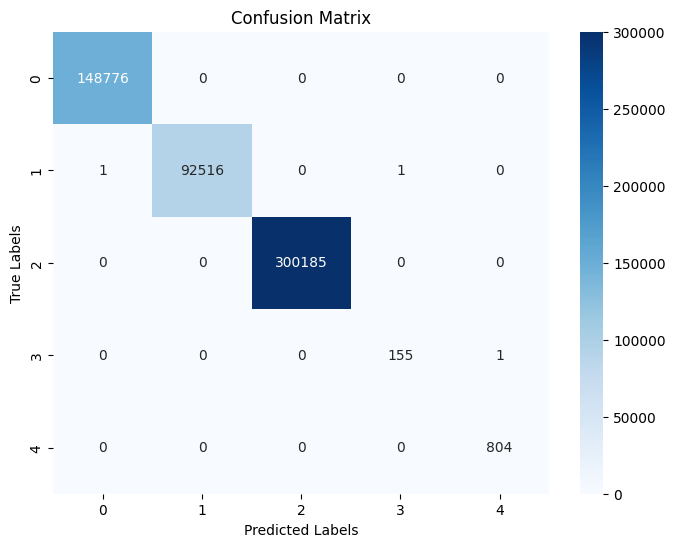

In [9]:
#cnn_gru_mdpi.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2)
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_cnn_gru_mdpi_type_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [10]:
print(f"Accuracy for 5 class classification cnn_gru_mdpi_bfore fl: {accuracy:.4f}")
print(f"Precision for 5 class classification cnn_gru_mdpi_bfore fl: {precision:.4f}")
print(f"Recall for 5 class classification cnn_gru_mdpi_bfore fl: {recall:.4f}")
print(f"F1 Score for 5 class classification cnn_gru_mdpi_bfore fl: {f1:.4f}")
print(f"MCC for 5 class classification cnn_gru_mdpi_bfore fl: {mcc:.4f}")

Accuracy for 5 class classification cnn_gru_mdpi_bfore fl: 1.0000
Precision for 5 class classification cnn_gru_mdpi_bfore fl: 0.9985
Recall for 5 class classification cnn_gru_mdpi_bfore fl: 0.9987
F1 Score for 5 class classification cnn_gru_mdpi_bfore fl: 0.9986
MCC for 5 class classification cnn_gru_mdpi_bfore fl: 1.0000


1st fl round cnn_gru_mdpi type

Epoch 1/5
31630/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9930 - loss: 0.0620
Epoch 1: val_loss improved from inf to 0.00014, saving model to D:/linthoi/FL_models/new/client1/type/client1_cnn_gru_mdpi_type_1stround_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 129s 4ms/step - accuracy: 0.9930 - loss: 0.0620 - val_accuracy: 1.0000 - val_loss: 1.3996e-04
Epoch 2/5
31628/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 1.3874e-04
Epoch 2: val_loss did not improve from 0.00014
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 124s 4ms/step - accuracy: 1.0000 - loss: 1.3876e-04 - val_accuracy: 1.0000 - val_loss: 1.8675e-04
Epoch 3/5
31629/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 7.2369e-05
Epoch 3: val_loss did not improve from 0.00014
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 109s 3ms/step - accuracy: 1.0000 - loss: 7.2408e-05 - val_accuracy: 1.0000 - val_loss: 1.6453e-04
Epoch 4/5
31634/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 2.0068e

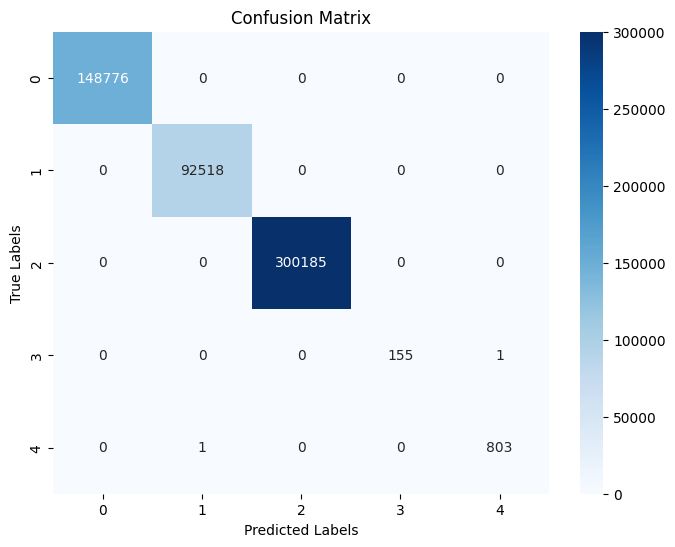

In [4]:

early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)

cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/1st_round_CNN_GRU_MDPI_Type_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_cnn_gru_mdpi_type_1stround_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [5]:
print(f"Accuracy for 5 class classification cnn_gru_mdpi_1stround fl: {accuracy:.4f}")
print(f"Precision for 5 class classification cnn_gru_mdpi_1stround fl: {precision:.4f}")
print(f"Recall for 5 class classification cnn_gru_mdpi_1stround fl: {recall:.4f}")
print(f"F1 Score for 5 class classification cnn_gru_mdpi_1stround fl: {f1:.4f}")
print(f"MCC for 5 class classification cnn_gru_mdpi_1stround fl: {mcc:.4f}")

Accuracy for 5 class classification cnn_gru_mdpi_1stround fl: 1.0000
Precision for 5 class classification cnn_gru_mdpi_1stround fl: 0.9997
Recall for 5 class classification cnn_gru_mdpi_1stround fl: 0.9985
F1 Score for 5 class classification cnn_gru_mdpi_1stround fl: 0.9991
MCC for 5 class classification cnn_gru_mdpi_1stround fl: 1.0000


In [ ]:
# y1_pred = model.predict(X1_test_r) 
# y1_pred_labels = np.argmax(y1_pred, axis=1)
# accuracy = accuracy_score(y1_test, y1_pred_labels)
# print(f"Accuracy Score: {accuracy}")

16952/16952 ━━━━━━━━━━━━━━━━━━━━ 27s 2ms/step
Accuracy Score: 0.999970503595796


2nd fl round cnn_gru_model (type)

Epoch 1/5
31638/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9942 - loss: 0.0616
Epoch 1: val_loss improved from inf to 0.00014, saving model to D:/linthoi/FL_models/new/client1/type/client1_cnn_gru_mdpi_type_2ndround_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 106s 3ms/step - accuracy: 0.9942 - loss: 0.0616 - val_accuracy: 1.0000 - val_loss: 1.3680e-04
Epoch 2/5
31628/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 3.2867e-04
Epoch 2: val_loss did not improve from 0.00014
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 107s 3ms/step - accuracy: 1.0000 - loss: 3.2862e-04 - val_accuracy: 1.0000 - val_loss: 1.9072e-04
Epoch 3/5
31636/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 6.0874e-05
Epoch 3: val_loss did not improve from 0.00014
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 112s 4ms/step - accuracy: 1.0000 - loss: 6.0882e-05 - val_accuracy: 1.0000 - val_loss: 2.1497e-04
Epoch 4/5
31638/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 1.0853e

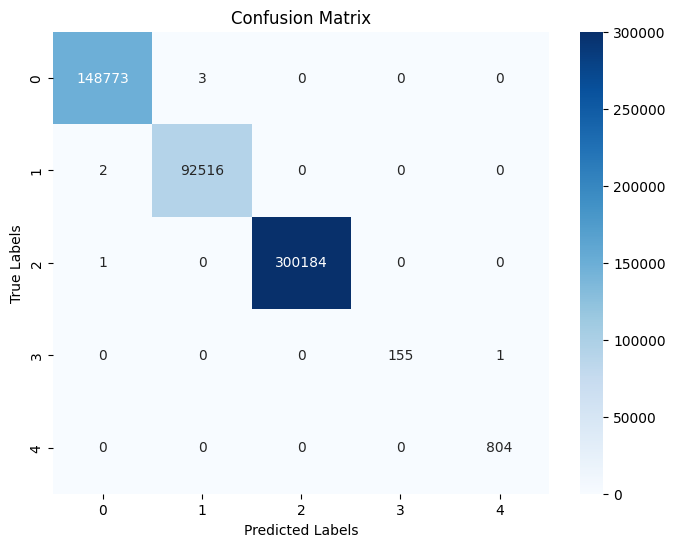

In [4]:

early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)

cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/2nd_round_CNN_GRU_MDPI_Type_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_cnn_gru_mdpi_type_2ndround_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [5]:
print(f"Accuracy for 5 class classification cnn_gru_mdpi_2ndround fl: {accuracy:.4f}")
print(f"Precision for 5 class classification cnn_gru_mdpi_2ndround fl: {precision:.4f}")
print(f"Recall for 5 class classification cnn_gru_mdpi_2ndround fl: {recall:.4f}")
print(f"F1 Score for 5 class classification cnn_gru_mdpi_2ndround fl: {f1:.4f}")
print(f"MCC for 5 class classification cnn_gru_mdpi_2ndround fl: {mcc:.4f}")

Accuracy for 5 class classification cnn_gru_mdpi_2ndround fl: 1.0000
Precision for 5 class classification cnn_gru_mdpi_2ndround fl: 0.9997
Recall for 5 class classification cnn_gru_mdpi_2ndround fl: 0.9987
F1 Score for 5 class classification cnn_gru_mdpi_2ndround fl: 0.9992
MCC for 5 class classification cnn_gru_mdpi_2ndround fl: 1.0000


3rd fl round cnn_gru_mdpi (type)

Epoch 1/5
31627/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9959 - loss: 0.0407
Epoch 1: val_loss improved from inf to 0.00016, saving model to D:/linthoi/FL_models/new/client1/type/client1_cnn_gru_mdpi_type_3rdround_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 93s 3ms/step - accuracy: 0.9959 - loss: 0.0407 - val_accuracy: 1.0000 - val_loss: 1.6291e-04
Epoch 2/5
31631/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 1.1102e-04
Epoch 2: val_loss improved from 0.00016 to 0.00013, saving model to D:/linthoi/FL_models/new/client1/type/client1_cnn_gru_mdpi_type_3rdround_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 112s 4ms/step - accuracy: 1.0000 - loss: 1.1103e-04 - val_accuracy: 1.0000 - val_loss: 1.2699e-04
Epoch 3/5
31639/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 1.2537e-04
Epoch 3: val_loss did not improve from 0.00013
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 119s 4ms/step - accuracy: 1.0000 - loss: 1.2537e-04 - val_accuracy: 1.0000 - v

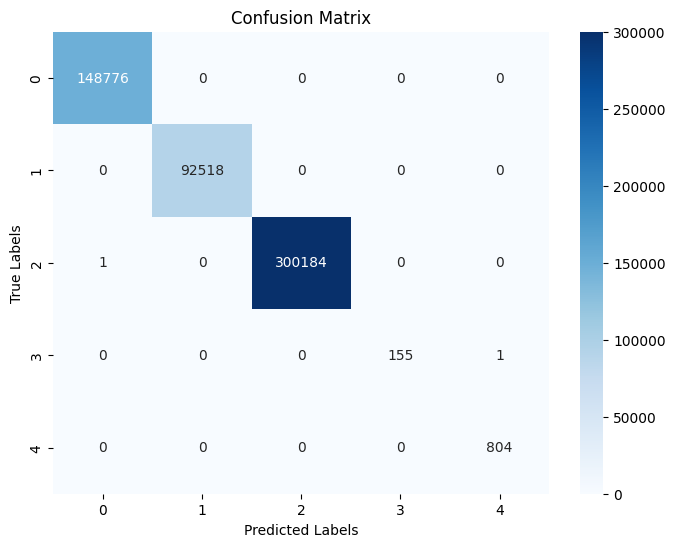

In [6]:

early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)

cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/3rd_round_CNN_GRU_MDPI_Type_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_cnn_gru_mdpi_type_3rdround_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 5 class classification cnn_gru_mdpi_3rdround fl: {accuracy:.4f}")
print(f"Precision for 5 class classification cnn_gru_mdpi_3rdround fl: {precision:.4f}")
print(f"Recall for 5 class classification cnn_gru_mdpi_3rdround fl: {recall:.4f}")
print(f"F1 Score for 5 class classification cnn_gru_mdpi_3rdround fl: {f1:.4f}")
print(f"MCC for 5 class classification cnn_gru_mdpi_3rdround fl: {mcc:.4f}")

Accuracy for 5 class classification cnn_gru_mdpi_3rdround fl: 1.0000
Precision for 5 class classification cnn_gru_mdpi_3rdround fl: 0.9998
Recall for 5 class classification cnn_gru_mdpi_3rdround fl: 0.9987
F1 Score for 5 class classification cnn_gru_mdpi_3rdround fl: 0.9992
MCC for 5 class classification cnn_gru_mdpi_3rdround fl: 1.0000


initialised cnn_gru binary (before fl)

In [23]:
X1=c2.iloc[:, :-3]
y1 = c2.iloc[:, -3]
X1 = scaler.fit_transform(X1)
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.3, random_state=42)
X1_train_r = X1_train.reshape((X1_train.shape[0], 1 , X1_train.shape[1]))
X1_test_r = X1_test.reshape((X1_test.shape[0], 1 ,X1_test.shape[1]))

In [27]:
y1.value_counts()

label
1    5930551
0     333559
Name: count, dtype: int64

Epoch 1/5
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9996 - loss: 0.0012
Epoch 1: val_loss improved from inf to 0.00000, saving model to D:/linthoi/FL_models/new/client1/binary/client1_cnn_gru_mdpi_bin_bfore_FL_weight_iid.keras
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 962s 9ms/step - accuracy: 0.9996 - loss: 0.0012 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 2/5
109621/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 5.9863e-13
Epoch 2: val_loss did not improve from 0.00000
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 936s 9ms/step - accuracy: 1.0000 - loss: 5.9863e-13 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 3/5
109617/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 7.3379e-14
Epoch 3: val_loss did not improve from 0.00000
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 764s 7ms/step - accuracy: 1.0000 - loss: 7.3387e-14 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 4/5
109612/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000

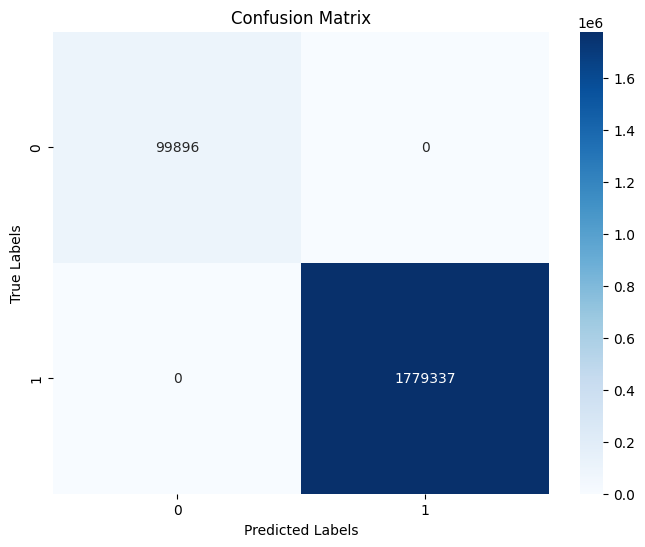

In [28]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Binary_glob_model/firstinitialized/CNN_GRU_MDPI_binary_glob_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/binary/client1_cnn_gru_mdpi_bin_bfore_FL_weight_iid.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [29]:
print(f"Accuracy for 2 class classification cnn_gru_mdpi_bforefl: {accuracy:.4f}")
print(f"Precision for 2 class classification cnn_gru_mdpi_bforefl fl: {precision:.4f}")
print(f"Recall for 2 class classification cnn_gru_mdpi_bforefl fl: {recall:.4f}")
print(f"F1 Score for 2 class classification cnn_gru_mdpi_bforefl fl: {f1:.4f}")
print(f"MCC for 2 class classification cnn_gru_mdpi_bforefl fl: {mcc:.4f}")

Accuracy for 2 class classification cnn_gru_mdpi_bforefl: 1.0000
Precision for 2 class classification cnn_gru_mdpi_bforefl fl: 1.0000
Recall for 2 class classification cnn_gru_mdpi_bforefl fl: 1.0000
F1 Score for 2 class classification cnn_gru_mdpi_bforefl fl: 1.0000
MCC for 2 class classification cnn_gru_mdpi_bforefl fl: 1.0000


before fl categorical cnn_gru_mdpi classification

In [31]:
X1=c2.iloc[:, :-3]
y1 = c2.iloc[:, -2]
X1 = scaler.fit_transform(X1)
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.3, random_state=42)
X1_train_r = X1_train.reshape((X1_train.shape[0], 1 , X1_train.shape[1]))
X1_test_r = X1_test.reshape((X1_test.shape[0], 1 ,X1_test.shape[1]))

In [36]:
y1

0          1
1          1
2          1
3          1
4          1
          ..
6264105    5
6264106    1
6264107    1
6264108    1
6264109    1
Name: category, Length: 6264110, dtype: int64

In [43]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/first_initialized_model/CNN_GRU_MDPI_cate_glob_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [41]:
cnn_gru_mdpi1.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_layer (Conv1D)           │ (None, 1, 64)          │         4,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpooling_layer (MaxPooling1D) │ (None, 1, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fully_connected_layer (Dense)   │ (None, 1, 128)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_layer (GRU)                 │ (None, 128)            │        99,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_layer (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 112,709 (440.27 KB)

 Trainable params: 112,709 (440.27 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
109621/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9950 - loss: 0.0175
Epoch 1: val_loss improved from inf to 0.00245, saving model to D:/linthoi/FL_models/new/client1/category/client1_cnn_gru_mdpi_cate_bfore_FL_weight_iid.keras
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 1182s 11ms/step - accuracy: 0.9950 - loss: 0.0175 - val_accuracy: 0.9991 - val_loss: 0.0024
Epoch 2/5
109619/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9989 - loss: 0.0034
Epoch 2: val_loss did not improve from 0.00245
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 1079s 10ms/step - accuracy: 0.9989 - loss: 0.0034 - val_accuracy: 0.9989 - val_loss: 0.0038
Epoch 3/5
109618/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9990 - loss: 0.0031
Epoch 3: val_loss improved from 0.00245 to 0.00193, saving model to D:/linthoi/FL_models/new/client1/category/client1_cnn_gru_mdpi_cate_bfore_FL_weight_iid.keras
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 934s 9ms/step - accuracy: 0.9990 - loss: 0.0031 - val_accuracy: 0.9992

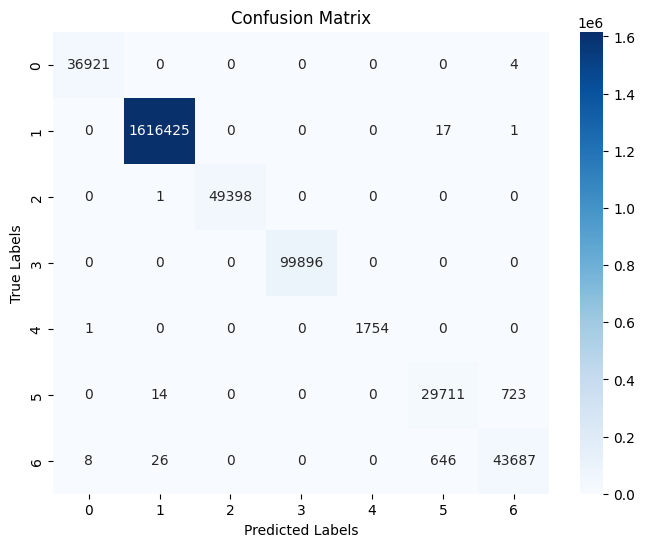

In [44]:

checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/category/client1_cnn_gru_mdpi_cate_bfore_FL_weight_iid.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [10]:
print(f"Accuracy for 4 class classification cnn_gru_mdpi_bforefl: {accuracy:.4f}")
print(f"Precision for 4 class classification cnn_gru_mdpi_bforefl fl: {precision:.4f}")
print(f"Recall for 4 class classification cnn_gru_mdpi_bforefl fl: {recall:.4f}")
print(f"F1 Score for 4 class classification cnn_gru_mdpi_bforefl fl: {f1:.4f}")
print(f"MCC for 4 class classification cnn_gru_mdpi_bforefl fl: {mcc:.4f}")

Accuracy for 4 class classification cnn_gru_mdpi_bforefl: 1.0000
Precision for 4 class classification cnn_gru_mdpi_bforefl fl: 1.0000
Recall for 4 class classification cnn_gru_mdpi_bforefl fl: 1.0000
F1 Score for 4 class classification cnn_gru_mdpi_bforefl fl: 1.0000
MCC for 4 class classification cnn_gru_mdpi_bforefl fl: 1.0000


PCC_CNN binary before fl

In [30]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
cnn_gru_mdpi1 = load_model(r'D:\linthoi\FL_models\new\glob_models\Binary_glob_model\firstinitialized\pcc_cnn_bin_glob_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/binary/client2_pcc_cnn_ieee_binary_bfore_FL_weight_iid.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


Epoch 1/5
109619/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9995 - loss: 0.0017
Epoch 1: val_loss improved from inf to 0.00000, saving model to D:/linthoi/FL_models/new/client1/binary/client2_pcc_cnn_ieee_binary_bfore_FL_weight_iid.keras
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 1709s 16ms/step - accuracy: 0.9995 - loss: 0.0017 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 2/5
103824/109622 ━━━━━━━━━━━━━━━━━━━━ 58s 10ms/step - accuracy: 1.0000 - loss: 3.2703e-13

KeyboardInterrupt: 

In [ ]:
print(f"Accuracy for 2 class classification pcc_cnn_bin_bforeFL: {accuracy:.4f}")
print(f"Precision for 2 class classification pcc_cnn_bin_bforeFL fl: {precision:.4f}")
print(f"Recall for 2 class classification pcc_cnn_bin_bforeFL fl: {recall:.4f}")
print(f"F1 Score for 2 class classification pcc_cnn_bin_bforeFL fl: {f1:.4f}")
print(f"MCC for 2 class classification pcc_cnn_bin_bforeFL fl: {mcc:.4f}")

Accuracy for 2 class classification pcc_cnn_bin_bforeFL: 1.0000
Precision for 2 class classification pcc_cnn_bin_bforeFL fl: 1.0000
Recall for 2 class classification pcc_cnn_bin_bforeFL fl: 1.0000
F1 Score for 2 class classification pcc_cnn_bin_bforeFL fl: 1.0000
MCC for 2 class classification pcc_cnn_bin_bforeFL fl: 1.0000


PCC CNN 4 class classification (category) before fl

Epoch 1/3
31641/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9918 - loss: 0.0233
Epoch 1: val_loss improved from inf to 0.00334, saving model to D:/linthoi/FL_models/new/client1/category/client1_pcc_cnn_ieee_cate_bfore_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 192s 6ms/step - accuracy: 0.9918 - loss: 0.0233 - val_accuracy: 0.9990 - val_loss: 0.0033
Epoch 2/3
31639/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 2.4760e-04
Epoch 2: val_loss improved from 0.00334 to 0.00000, saving model to D:/linthoi/FL_models/new/client1/category/client1_pcc_cnn_ieee_cate_bfore_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 182s 6ms/step - accuracy: 1.0000 - loss: 2.4760e-04 - val_accuracy: 1.0000 - val_loss: 3.5679e-08
Epoch 3/3
31641/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 1.6172e-04
Epoch 3: val_loss improved from 0.00000 to 0.00000, saving model to D:/linthoi/FL_models/new/client1/category/client1_pcc_cnn_ieee_cate_bfore_FL_weight.keras
3

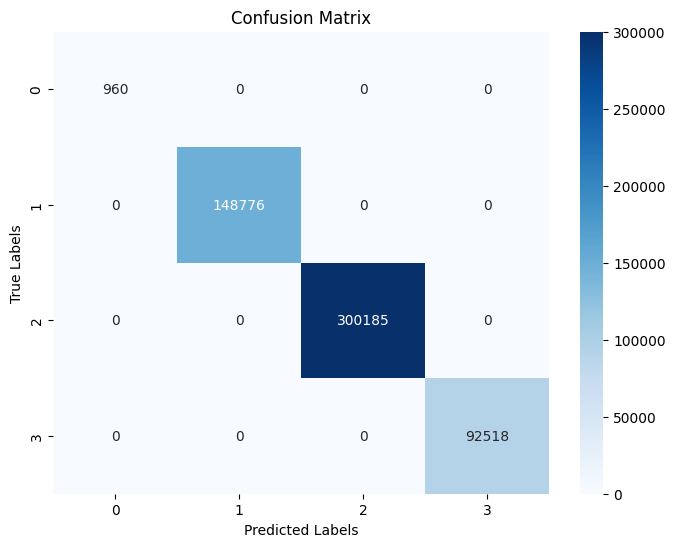

In [5]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
pcc_cnn_cate = load_model(r'D:\linthoi\FL_models\new\glob_models\Category_glob_model\firstinitialized\pcc_cnn_cate_glob_model.h5')
pcc_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/category/client1_pcc_cnn_ieee_cate_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn_cate.fit(X1_train, y1_train, epochs=3, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = pcc_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 4 class classification pcc_cnn_cate_bforeFL: {accuracy:.4f}")
print(f"Precision for 4 class classification pcc_cnn_cate_bforeFL fl: {precision:.4f}")
print(f"Recall for 4 class classification pcc_cnn_cate_bforeFL fl: {recall:.4f}")
print(f"F1 Score for 4 class classification pcc_cnn_cate_bforeFL fl: {f1:.4f}")
print(f"MCC for 4 class classification pcc_cnn_cate_bforeFL fl: {mcc:.4f}")

Accuracy for 4 class classification pcc_cnn_cate_bforeFL: 1.0000
Precision for 4 class classification pcc_cnn_cate_bforeFL fl: 1.0000
Recall for 4 class classification pcc_cnn_cate_bforeFL fl: 1.0000
F1 Score for 4 class classification pcc_cnn_cate_bforeFL fl: 1.0000
MCC for 4 class classification pcc_cnn_cate_bforeFL fl: 1.0000


PCC_CNN type classification before FL

Epoch 1/3
31634/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9917 - loss: 0.0249
Epoch 1: val_loss improved from inf to 0.00015, saving model to D:/linthoi/FL_models/new/client1/type/client1_pcc_cnn_ieee_type_bfore_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 145s 5ms/step - accuracy: 0.9917 - loss: 0.0249 - val_accuracy: 1.0000 - val_loss: 1.5066e-04
Epoch 2/3
31640/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9999 - loss: 4.1459e-04
Epoch 2: val_loss improved from 0.00015 to 0.00014, saving model to D:/linthoi/FL_models/new/client1/type/client1_pcc_cnn_ieee_type_bfore_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 180s 6ms/step - accuracy: 0.9999 - loss: 4.1460e-04 - val_accuracy: 1.0000 - val_loss: 1.4359e-04
Epoch 3/3
31632/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 1.9032e-04
Epoch 3: val_loss did not improve from 0.00014
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 212s 7ms/step - accuracy: 1.0000 - loss: 1.9032e-04 - val_accuracy: 1.0000 - val_lo

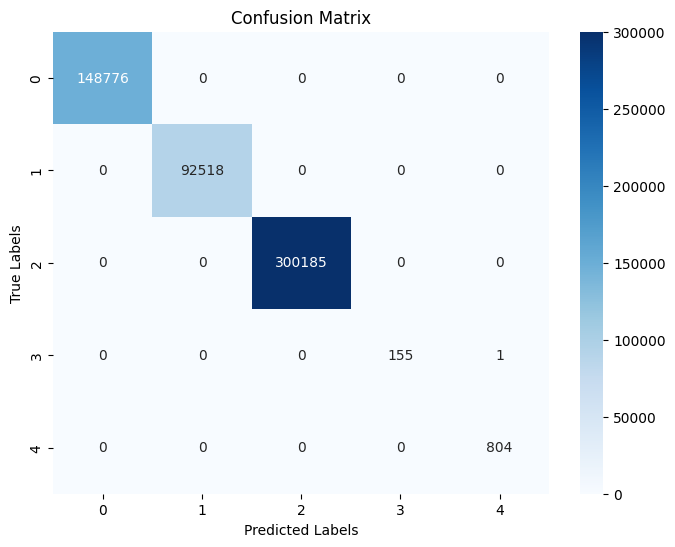

In [5]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
pcc_cnn_type = load_model(r'D:\linthoi\FL_models\new\glob_models\Type_glob_model\firstinitialized\pcc_cnn_type_glob_model.h5')
pcc_cnn_type.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_pcc_cnn_ieee_type_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn_type.fit(X1_train, y1_train, epochs=3, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = pcc_cnn_type.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [6]:
print(f"Accuracy for 4 class classification pcc_cnn_type_bforeFL: {accuracy:.4f}")
print(f"Precision for 4 class classification pcc_cnn_type_bforeFL fl: {precision:.4f}")
print(f"Recall for 4 class classification pcc_cnn_type_bforeFL fl: {recall:.4f}")
print(f"F1 Score for 4 class classification pcc_cnn_type_bforeFL fl: {f1:.4f}")
print(f"MCC for 4 class classification pcc_cnn_type_bforeFL fl: {mcc:.4f}")

Accuracy for 4 class classification pcc_cnn_type_bforeFL: 1.0000
Precision for 4 class classification pcc_cnn_type_bforeFL fl: 0.9998
Recall for 4 class classification pcc_cnn_type_bforeFL fl: 0.9987
F1 Score for 4 class classification pcc_cnn_type_bforeFL fl: 0.9992
MCC for 4 class classification pcc_cnn_type_bforeFL fl: 1.0000


1st fl round pcc_cnn type classification

Epoch 1/3
31639/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9953 - loss: 0.0200
Epoch 1: val_loss improved from inf to 0.00013, saving model to D:/linthoi/FL_models/new/client1/type/client1_pcc_cnn_ieee_type_1st_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 182s 6ms/step - accuracy: 0.9953 - loss: 0.0200 - val_accuracy: 1.0000 - val_loss: 1.2772e-04
Epoch 2/3
31633/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 8.4943e-05
Epoch 2: val_loss did not improve from 0.00013
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 200s 6ms/step - accuracy: 1.0000 - loss: 8.4968e-05 - val_accuracy: 1.0000 - val_loss: 1.4631e-04
Epoch 3/3
31637/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 9.2271e-05
Epoch 3: val_loss did not improve from 0.00013
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 209s 7ms/step - accuracy: 1.0000 - loss: 9.2268e-05 - val_accuracy: 0.9995 - val_loss: 0.0072
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 53s 3m

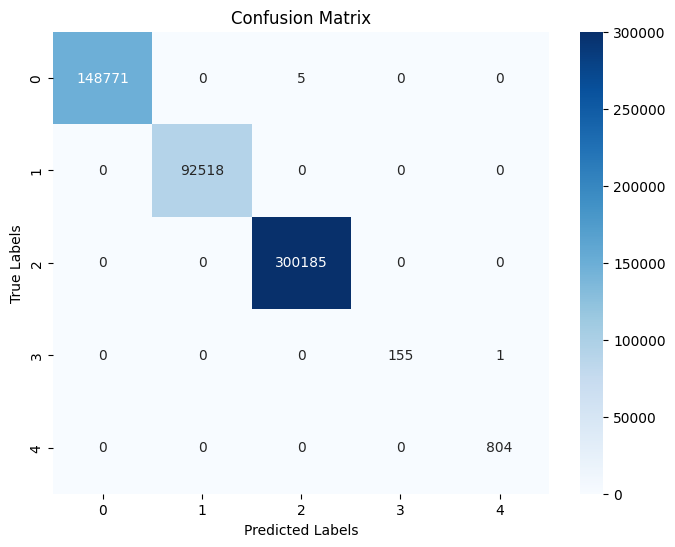

In [7]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
pcc_cnn_type = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/1st_round_pcc_cnn_type_glob_model.h5')
pcc_cnn_type.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_pcc_cnn_ieee_type_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn_type.fit(X1_train, y1_train, epochs=3, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = pcc_cnn_type.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [8]:
print(f"Accuracy for 5 class classification pcc_cnn_type_bforeFL: {accuracy:.4f}")
print(f"Precision for 5 class classification pcc_cnn_type_bforeFL fl: {precision:.4f}")
print(f"Recall for 5 class classification pcc_cnn_type_bforeFL fl: {recall:.4f}")
print(f"F1 Score for 5 class classification pcc_cnn_type_bforeFL fl: {f1:.4f}")
print(f"MCC for 5 class classification pcc_cnn_type_bforeFL fl: {mcc:.4f}")

Accuracy for 5 class classification pcc_cnn_type_bforeFL: 1.0000
Precision for 5 class classification pcc_cnn_type_bforeFL fl: 0.9997
Recall for 5 class classification pcc_cnn_type_bforeFL fl: 0.9987
F1 Score for 5 class classification pcc_cnn_type_bforeFL fl: 0.9992
MCC for 5 class classification pcc_cnn_type_bforeFL fl: 1.0000


2nd fl round type classification pcc_cnn

Epoch 1/3
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9946 - loss: 0.0269
Epoch 1: val_loss improved from inf to 0.00014, saving model to D:/linthoi/FL_models/new/client1/type/client1_pcc_cnn_ieee_type_2nd_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 259s 8ms/step - accuracy: 0.9946 - loss: 0.0269 - val_accuracy: 1.0000 - val_loss: 1.4241e-04
Epoch 2/3
31636/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 1.2444e-04
Epoch 2: val_loss improved from 0.00014 to 0.00013, saving model to D:/linthoi/FL_models/new/client1/type/client1_pcc_cnn_ieee_type_2nd_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 257s 8ms/step - accuracy: 1.0000 - loss: 1.2444e-04 - val_accuracy: 1.0000 - val_loss: 1.3154e-04
Epoch 3/3
31641/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 7.6049e-05
Epoch 3: val_loss did not improve from 0.00013
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 262s 8ms/step - accuracy: 1.0000 - loss: 7.6058e-05 - val_accuracy: 1.0000 - val_loss: 

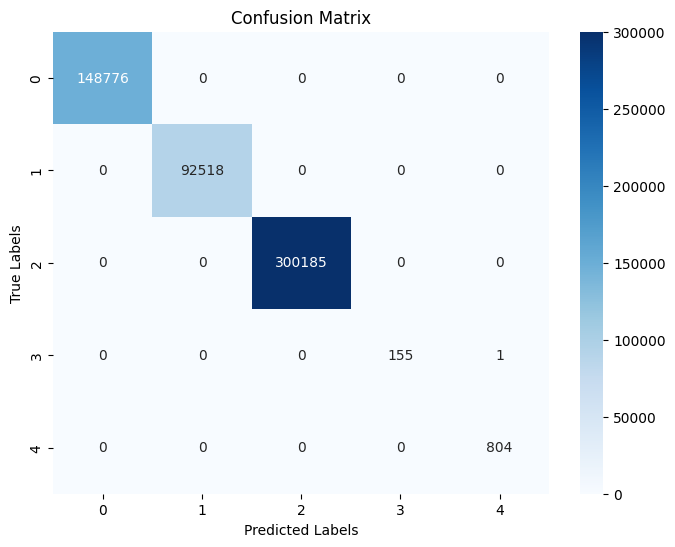

In [4]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
pcc_cnn_type = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/2nd_round_pcc_cnn_type_glob_model.h5')
pcc_cnn_type.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_pcc_cnn_ieee_type_2nd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn_type.fit(X1_train, y1_train, epochs=3, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = pcc_cnn_type.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [5]:
print(f"Accuracy for 5 class classification pcc_cnn_type_2nd FL: {accuracy:.4f}")
print(f"Precision for 5 class classification pcc_cnn_type_2nd fl: {precision:.4f}")
print(f"Recall for 5 class classification pcc_cnn_type_2nd fl: {recall:.4f}")
print(f"F1 Score for 5 class classification pcc_cnn_type_2nd fl: {f1:.4f}")
print(f"MCC for 5 class classification pcc_cnn_type_2nd fl: {mcc:.4f}")

Accuracy for 5 class classification pcc_cnn_type_2nd FL: 1.0000
Precision for 5 class classification pcc_cnn_type_2nd fl: 0.9998
Recall for 5 class classification pcc_cnn_type_2nd fl: 0.9987
F1 Score for 5 class classification pcc_cnn_type_2nd fl: 0.9992
MCC for 5 class classification pcc_cnn_type_2nd fl: 1.0000


3rd fl round pcc_cnn type classification

Epoch 1/3
31641/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9959 - loss: 0.0171
Epoch 1: val_loss improved from inf to 0.00009, saving model to D:/linthoi/FL_models/new/client1/type/client1_pcc_cnn_ieee_type_3rd_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 200s 6ms/step - accuracy: 0.9959 - loss: 0.0171 - val_accuracy: 1.0000 - val_loss: 8.7607e-05
Epoch 2/3
31637/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 1.0526e-04
Epoch 2: val_loss did not improve from 0.00009
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 212s 7ms/step - accuracy: 1.0000 - loss: 1.0525e-04 - val_accuracy: 1.0000 - val_loss: 2.0378e-04
Epoch 3/3
31642/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 1.1085e-04
Epoch 3: val_loss did not improve from 0.00009
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 213s 7ms/step - accuracy: 1.0000 - loss: 1.1085e-04 - val_accuracy: 0.9987 - val_loss: 0.0083
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 55s 3m

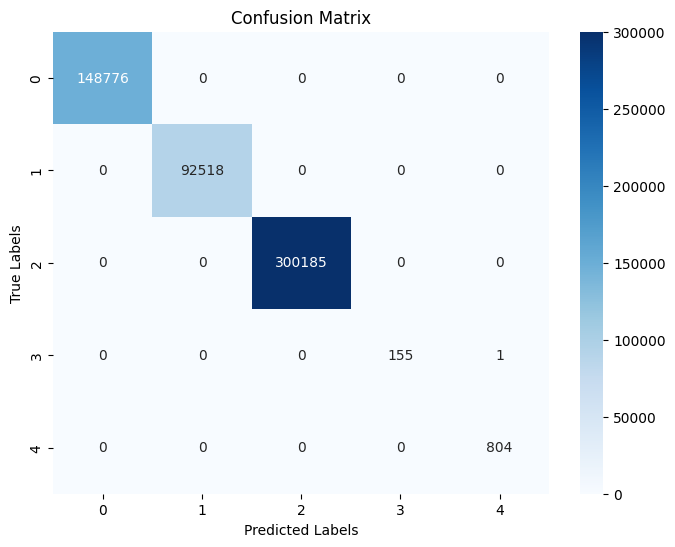

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
pcc_cnn_type = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/3rd_round_pcc_cnn_type_glob_model.h5')
pcc_cnn_type.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_pcc_cnn_ieee_type_3rd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn_type.fit(X1_train, y1_train, epochs=3, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = pcc_cnn_type.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [9]:
print(f"Accuracy for 5 class classification pcc_cnn_type_3rd FL: {accuracy:.4f}")
print(f"Precision for 5 class classification pcc_cnn_type_3rd fl: {precision:.4f}")
print(f"Recall for 5 class classification pcc_cnn_type_3rd fl: {recall:.4f}")
print(f"F1 Score for 5 class classification pcc_cnn_type_3rd fl: {f1:.4f}")
print(f"MCC for 5 class classification pcc_cnn_type_3rd fl: {mcc:.4f}")

Accuracy for 5 class classification pcc_cnn_type_3rd FL: 1.0000
Precision for 5 class classification pcc_cnn_type_3rd fl: 0.9998
Recall for 5 class classification pcc_cnn_type_3rd fl: 0.9987
F1 Score for 5 class classification pcc_cnn_type_3rd fl: 0.9992
MCC for 5 class classification pcc_cnn_type_3rd fl: 1.0000


FELIDS DNN 4 class classification before FL (category)

31641/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9907 - loss: 0.0291
Epoch 1: val_loss improved from inf to 0.00000, saving model to D:/linthoi/FL_models/new/client1/category/client1_FELIDS_dnn_bfore_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 114s 4ms/step - accuracy: 0.9907 - loss: 0.0291 - val_accuracy: 1.0000 - val_loss: 1.0098e-07
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 24s 1ms/step
Accuracy Score: 1.0


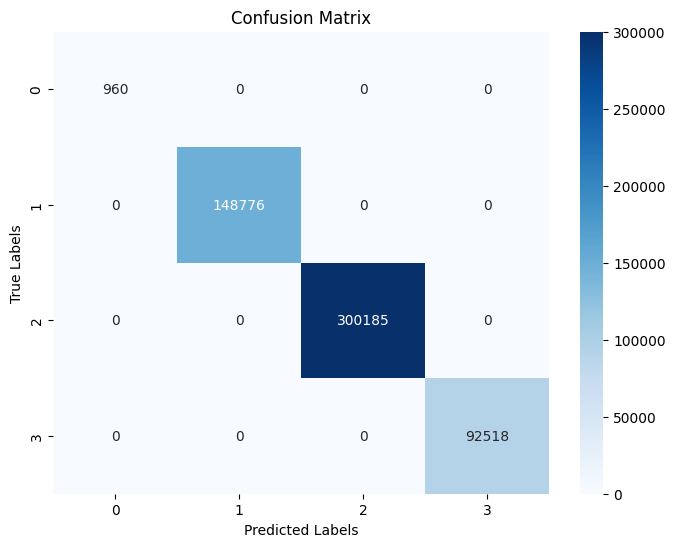

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_cate = load_model(r'D:\linthoi\FL_models\new\glob_models\Category_glob_model\firstinitialized\felids_dnn_cate.h5')
felids_dnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/category/client1_FELIDS_dnn_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 4 class classification felids_dnn_cate before fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_dnn_cate before fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_dnn_cate before fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_dnn_cate before fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_dnn_cate before fl: {mcc:.4f}")

Accuracy for 4 class classification felids_dnn_cate before fl: 1.0000
Precision for 4 class classification felids_dnn_cate before fl: 1.0000
Recall for 4 class classification felids_dnn_cate before fl: 1.0000
F1 Score for 4 class classification felids_dnn_cate before fl: 1.0000
MCC for 4 class classification felids_dnn_cate before fl: 1.0000


Felids DNN_Type classification before FL

31619/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9804 - loss: 0.0646
Epoch 1: val_loss improved from inf to 0.00025, saving model to D:/linthoi/FL_models/new/client1/type/client1_felids_dnn_type_bfore_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 74s 2ms/step - accuracy: 0.9804 - loss: 0.0646 - val_accuracy: 1.0000 - val_loss: 2.4914e-04
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 19s 1ms/step
Accuracy Score: 0.9999907823736862


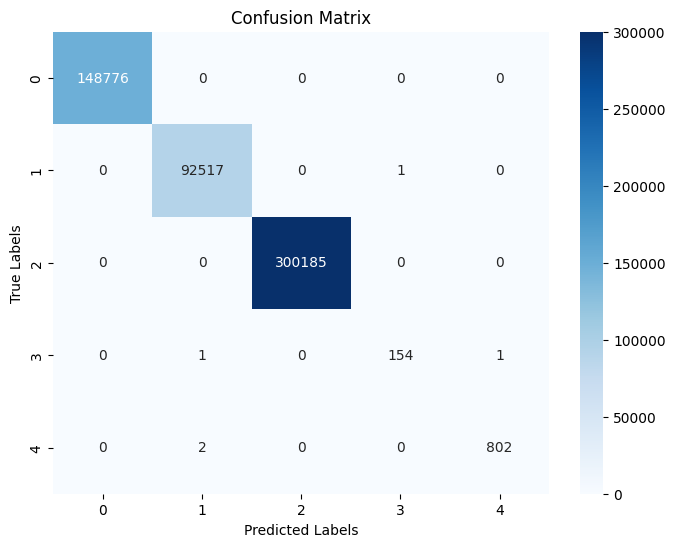

In [4]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_cate = load_model(r'D:\linthoi\FL_models\new\glob_models\Type_glob_model\firstinitialized\felids_dnn_type.h5')
felids_dnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_felids_dnn_type_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [5]:
print(f"Accuracy for 4 class classification felids_dnn_type before fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_dnn_type before fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_dnn_type before fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_dnn_type before fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_dnn_type before fl: {mcc:.4f}")

Accuracy for 4 class classification felids_dnn_type before fl: 1.0000
Precision for 4 class classification felids_dnn_type before fl: 0.9985
Recall for 4 class classification felids_dnn_type before fl: 0.9969
F1 Score for 4 class classification felids_dnn_type before fl: 0.9977
MCC for 4 class classification felids_dnn_type before fl: 1.0000


1st round felids dnn type classification

31614/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9847 - loss: 0.0970
Epoch 1: val_loss improved from inf to 0.00018, saving model to D:/linthoi/FL_models/new/client1/type/client1_felids_dnn_type_1st_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 79s 2ms/step - accuracy: 0.9847 - loss: 0.0969 - val_accuracy: 1.0000 - val_loss: 1.7780e-04
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 20s 1ms/step
Accuracy Score: 0.9999944694242118


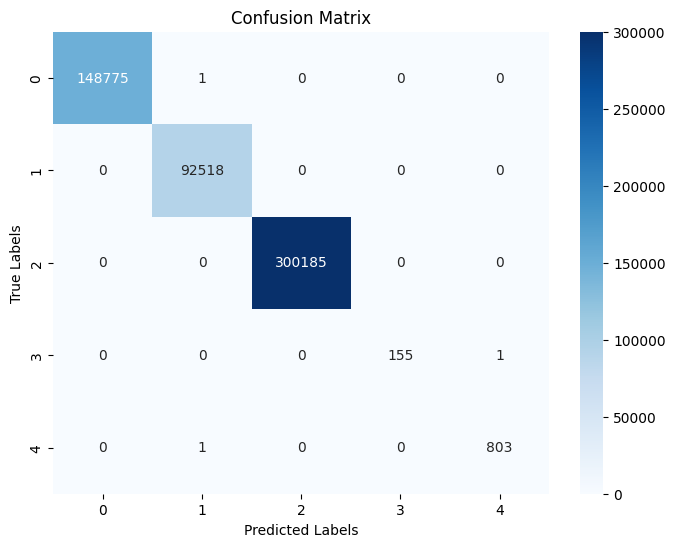

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/1st_round_felids_dnn_type_glob_model.h5')
felids_dnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_felids_dnn_type_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 4 class classification felids_dnn_type 1st fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_dnn_type 1st fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_dnn_type 1st fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_dnn_type 1st fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_dnn_type 1st fl: {mcc:.4f}")

Accuracy for 4 class classification felids_dnn_type 1st fl: 1.0000
Precision for 4 class classification felids_dnn_type 1st fl: 0.9997
Recall for 4 class classification felids_dnn_type 1st fl: 0.9985
F1 Score for 4 class classification felids_dnn_type 1st fl: 0.9991
MCC for 4 class classification felids_dnn_type 1st fl: 1.0000


felids dnn type 2nd fl round

31635/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9854 - loss: 0.0813
Epoch 1: val_loss improved from inf to 0.00020, saving model to D:/linthoi/FL_models/new/client1/type/client1_felids_dnn_type_2nd_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 91s 3ms/step - accuracy: 0.9854 - loss: 0.0813 - val_accuracy: 1.0000 - val_loss: 1.9593e-04
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 21s 1ms/step
Accuracy Score: 0.999985251797898


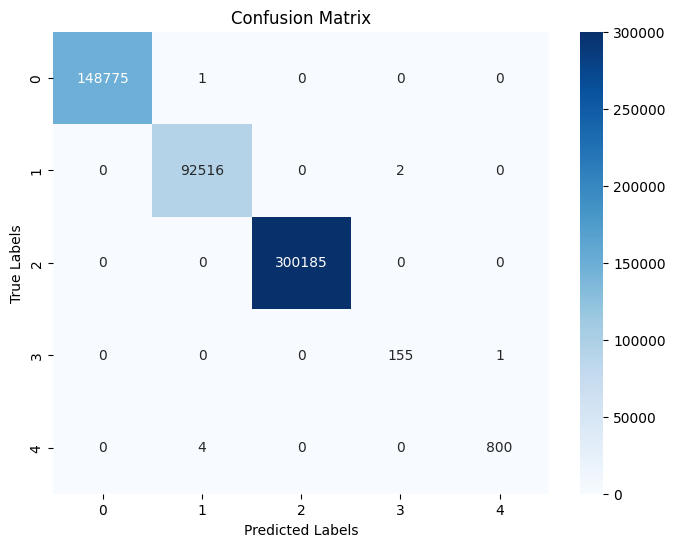

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/2nd_round_felids_dnn_type_glob_model.h5')
felids_dnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_felids_dnn_type_2nd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [9]:
print(f"Accuracy for 4 class classification felids_dnn_type 2nd fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_dnn_type 2nd fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_dnn_type 2nd fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_dnn_type 2nd fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_dnn_type 2nd fl: {mcc:.4f}")

Accuracy for 4 class classification felids_dnn_type 2nd fl: 1.0000
Precision for 4 class classification felids_dnn_type 2nd fl: 0.9972
Recall for 4 class classification felids_dnn_type 2nd fl: 0.9977
F1 Score for 4 class classification felids_dnn_type 2nd fl: 0.9975
MCC for 4 class classification felids_dnn_type 2nd fl: 1.0000


3rd felids dnn type classification round

31637/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9866 - loss: 0.0634
Epoch 1: val_loss improved from inf to 0.00022, saving model to D:/linthoi/FL_models/new/client1/type/client1_felids_dnn_type_3rd_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 87s 3ms/step - accuracy: 0.9866 - loss: 0.0634 - val_accuracy: 1.0000 - val_loss: 2.2337e-04
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 23s 1ms/step
Accuracy Score: 0.9999889388484235


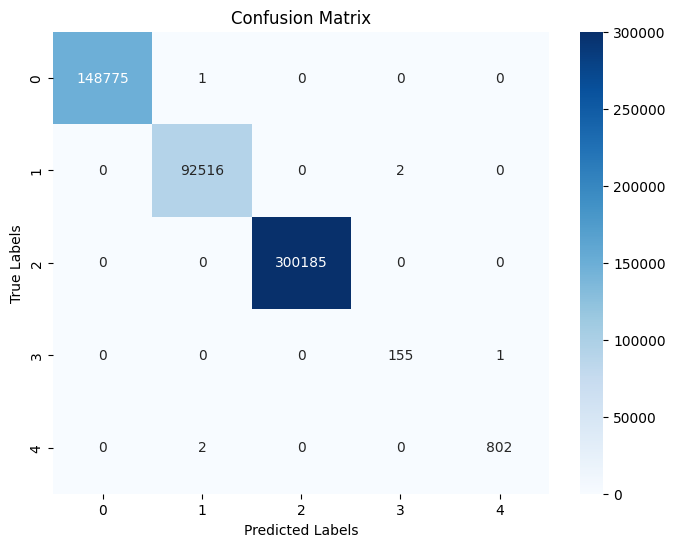

In [10]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/3rd_round_felids_dnn_type_glob_model.h5')
felids_dnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_felids_dnn_type_3rd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [11]:
print(f"Accuracy for 4 class classification felids_dnn_type 3rd fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_dnn_type 3rd fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_dnn_type 3rd fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_dnn_type 3rd fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_dnn_type 3rd fl: {mcc:.4f}")

Accuracy for 4 class classification felids_dnn_type 3rd fl: 1.0000
Precision for 4 class classification felids_dnn_type 3rd fl: 0.9972
Recall for 4 class classification felids_dnn_type 3rd fl: 0.9982
F1 Score for 4 class classification felids_dnn_type 3rd fl: 0.9977
MCC for 4 class classification felids_dnn_type 3rd fl: 1.0000


FELIDS CNN 4 class classification (category)

31638/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9479 - loss: 0.1244
Epoch 1: val_loss improved from inf to 0.00043, saving model to D:/linthoi/FL_models/new/client1/category/client1_FELIDS_cnn_bfore_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 168s 5ms/step - accuracy: 0.9479 - loss: 0.1244 - val_accuracy: 0.9999 - val_loss: 4.2669e-04
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 44s 3ms/step
Accuracy Score: 0.9999539118684313


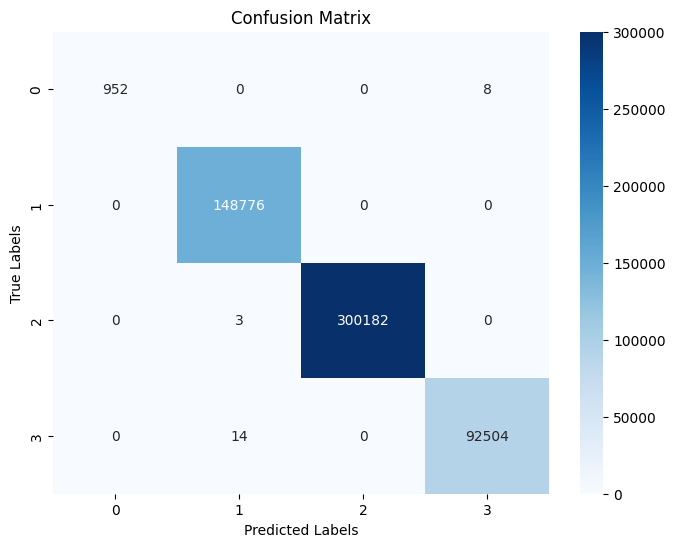

In [8]:

early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_cate = load_model(r'D:\linthoi\FL_models\new\glob_models\Category_glob_model\firstinitialized\felids_cnn_cate_glob_model.h5')
felids_dnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/category/client1_FELIDS_cnn_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [9]:
print(f"Accuracy for 4 class classification felids_cnn_cate before fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_cnn_cate before fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_cnn_cate before fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_cnn_cate before fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_cnn_cate before fl: {mcc:.4f}")

Accuracy for 4 class classification felids_cnn_cate before fl: 1.0000
Precision for 4 class classification felids_cnn_cate before fl: 0.9999
Recall for 4 class classification felids_cnn_cate before fl: 0.9979
F1 Score for 4 class classification felids_cnn_cate before fl: 0.9989
MCC for 4 class classification felids_cnn_cate before fl: 0.9999


1st fl felids cnn category classification

31637/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9886 - loss: 0.0286
Epoch 1: val_loss improved from inf to 0.00061, saving model to D:/linthoi/FL_models/new/client1/category/client1_FELIDS_cnn_CATE_1st_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 184s 6ms/step - accuracy: 0.9886 - loss: 0.0286 - val_accuracy: 0.9999 - val_loss: 6.0541e-04
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 42s 2ms/step
Accuracy Score: 0.9999612859694823


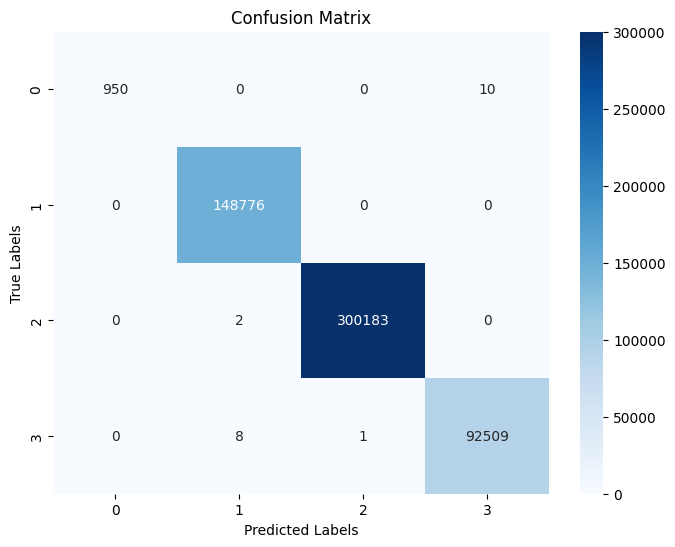

In [4]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/1st_round_felids_cnn_cate_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/category/client1_FELIDS_cnn_CATE_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [5]:
print(f"Accuracy for 4 class classification felids_cnn_cate 1st fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_cnn_cate 1st fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_cnn_cate 1st fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_cnn_cate 1st fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_cnn_cate 1st fl: {mcc:.4f}")

Accuracy for 4 class classification felids_cnn_cate 1st fl: 1.0000
Precision for 4 class classification felids_cnn_cate 1st fl: 1.0000
Recall for 4 class classification felids_cnn_cate 1st fl: 0.9974
F1 Score for 4 class classification felids_cnn_cate 1st fl: 0.9987
MCC for 4 class classification felids_cnn_cate 1st fl: 0.9999


2nd round felids cnn cate

31638/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9972 - loss: 0.0103
Epoch 1: val_loss improved from inf to 0.00000, saving model to D:/linthoi/FL_models/new/client1/category/client1_FELIDS_cnn_CATE_2nd_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 203s 6ms/step - accuracy: 0.9972 - loss: 0.0103 - val_accuracy: 1.0000 - val_loss: 4.9874e-06
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 53s 3ms/step
Accuracy Score: 0.9999981564747372


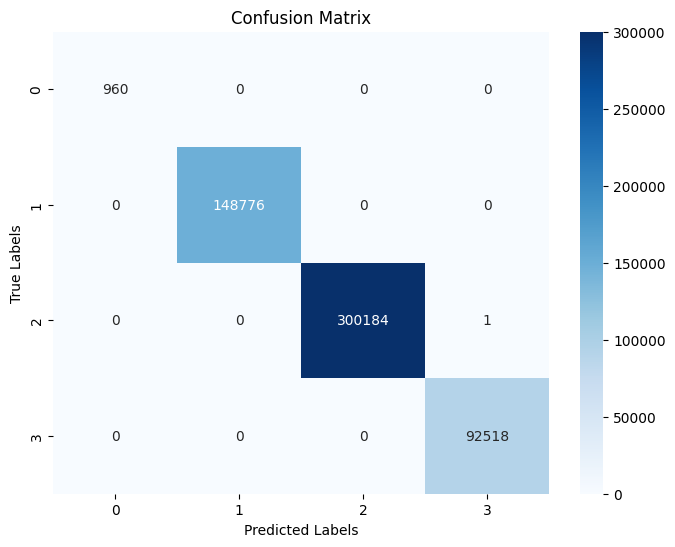

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/2nd_round_felids_cnn_cate_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/category/client1_FELIDS_cnn_CATE_2nd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 4 class classification felids_cnn_cate 2nd fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_cnn_cate 2nd fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_cnn_cate 2nd fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_cnn_cate 2nd fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_cnn_cate 2nd fl: {mcc:.4f}")

Accuracy for 4 class classification felids_cnn_cate 2nd fl: 1.0000
Precision for 4 class classification felids_cnn_cate 2nd fl: 1.0000
Recall for 4 class classification felids_cnn_cate 2nd fl: 1.0000
F1 Score for 4 class classification felids_cnn_cate 2nd fl: 1.0000
MCC for 4 class classification felids_cnn_cate 2nd fl: 1.0000


felids cnn type before fl

31642/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9434 - loss: 0.1367
Epoch 1: val_loss improved from inf to 0.00221, saving model to D:/linthoi/FL_models/new/client1/type/client1_FELIDS_cnn_type_bfore_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 180s 6ms/step - accuracy: 0.9434 - loss: 0.1367 - val_accuracy: 0.9996 - val_loss: 0.0022
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 40s 2ms/step
Accuracy Score: 0.999670008977968


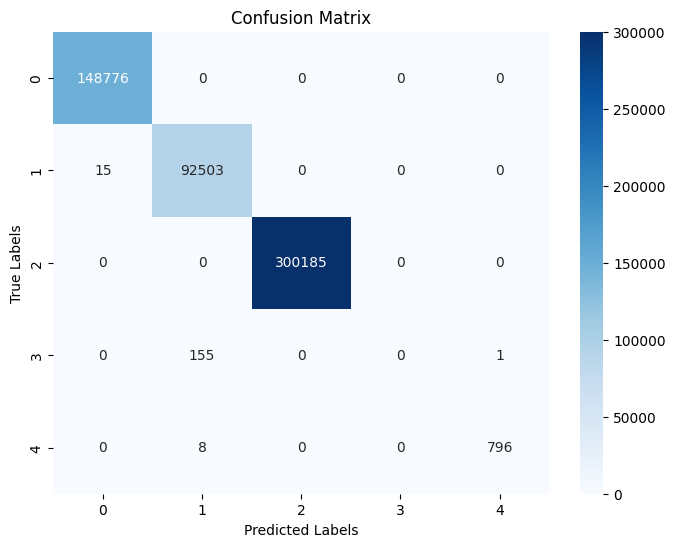

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [12]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model(r'D:\linthoi\FL_models\new\glob_models\Type_glob_model\firstinitialized\felids_cnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_FELIDS_cnn_type_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [13]:
print(f"Accuracy for 5 class classification felids_cnn_type before fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_cnn_type before fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_cnn_type before fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_cnn_type before fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_cnn_type before fl: {mcc:.4f}")

Accuracy for 5 class classification felids_cnn_type before fl: 0.9997
Precision for 5 class classification felids_cnn_type before fl: 0.7994
Recall for 5 class classification felids_cnn_type before fl: 0.7980
F1 Score for 5 class classification felids_cnn_type before fl: 0.7987
MCC for 5 class classification felids_cnn_type before fl: 0.9994


1st fl round felids cnn type 

31635/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9884 - loss: 0.0340
Epoch 1: val_loss improved from inf to 0.00154, saving model to D:/linthoi/FL_models/new/client1/type/client1_FELIDS_cnn_type_1st_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 170s 5ms/step - accuracy: 0.9884 - loss: 0.0340 - val_accuracy: 0.9997 - val_loss: 0.0015
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 45s 3ms/step
Accuracy Score: 0.9996902877558582


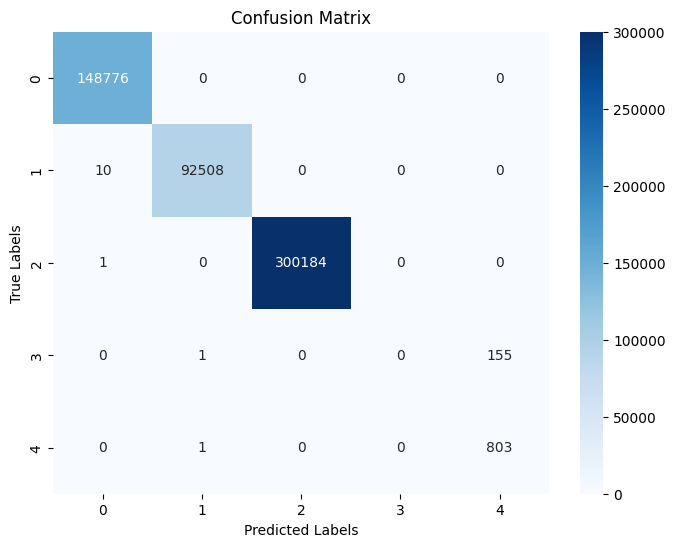

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [14]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/1st_round_felids_cnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_FELIDS_cnn_type_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [15]:
print(f"Accuracy for 5 class classification felids_cnn_type 1st fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_cnn_type 1st fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_cnn_type 1st fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_cnn_type 1st fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_cnn_type 1st fl: {mcc:.4f}")

Accuracy for 5 class classification felids_cnn_type 1st fl: 0.9997
Precision for 5 class classification felids_cnn_type 1st fl: 0.7676
Recall for 5 class classification felids_cnn_type 1st fl: 0.7997
F1 Score for 5 class classification felids_cnn_type 1st fl: 0.7823
MCC for 5 class classification felids_cnn_type 1st fl: 0.9995


2nd fl felids round cnn type

31643/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9928 - loss: 0.0208
Epoch 1: val_loss improved from inf to 0.00013, saving model to D:/linthoi/FL_models/new/client1/type/client1_FELIDS_cnn_type_2nd_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 210s 7ms/step - accuracy: 0.9928 - loss: 0.0208 - val_accuracy: 1.0000 - val_loss: 1.3069e-04
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 50s 3ms/step
Accuracy Score: 0.999977877696847


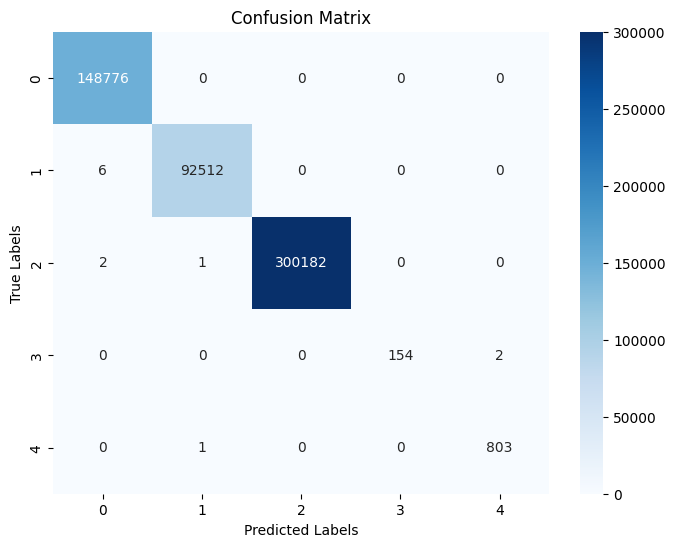

In [4]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/2nd_round_felids_cnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_FELIDS_cnn_type_2nd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [5]:
print(f"Accuracy for 5 class classification felids_cnn_type 2nd fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_cnn_type 2nd fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_cnn_type 2nd fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_cnn_type 2nd fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_cnn_type 2nd fl: {mcc:.4f}")

Accuracy for 5 class classification felids_cnn_type 2nd fl: 1.0000
Precision for 5 class classification felids_cnn_type 2nd fl: 0.9995
Recall for 5 class classification felids_cnn_type 2nd fl: 0.9972
F1 Score for 5 class classification felids_cnn_type 2nd fl: 0.9983
MCC for 5 class classification felids_cnn_type 2nd fl: 1.0000


3rd fl felids cnn type classification

31642/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9958 - loss: 0.0190
Epoch 1: val_loss improved from inf to 0.00046, saving model to D:/linthoi/FL_models/new/client1/type/client1_FELIDS_cnn_type_3rd_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 166s 5ms/step - accuracy: 0.9958 - loss: 0.0190 - val_accuracy: 0.9999 - val_loss: 4.5680e-04
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 49s 3ms/step
Accuracy Score: 0.9999594424442195


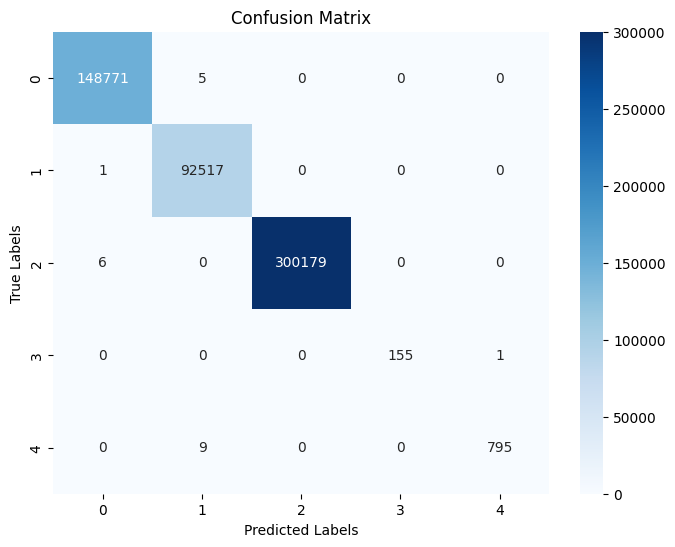

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/3rd_round_felids_cnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_FELIDS_cnn_type_3rd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 5 class classification felids_cnn_type 3rd fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_cnn_type 3rd fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_cnn_type 3rd fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_cnn_type 3rd fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_cnn_type 3rd fl: {mcc:.4f}")

Accuracy for 5 class classification felids_cnn_type 3rd fl: 1.0000
Precision for 5 class classification felids_cnn_type 3rd fl: 0.9997
Recall for 5 class classification felids_cnn_type 3rd fl: 0.9965
F1 Score for 5 class classification felids_cnn_type 3rd fl: 0.9981
MCC for 5 class classification felids_cnn_type 3rd fl: 0.9999


felids rnn category classification before fl

31643/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.9553 - loss: 0.1076
Epoch 1: val_loss improved from inf to 0.00001, saving model to D:/linthoi/FL_models/new/client1/category/client1_FELIDS_rnn_cate_bfore_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 1929s 61ms/step - accuracy: 0.9553 - loss: 0.1076 - val_accuracy: 1.0000 - val_loss: 8.0735e-06
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 281s 17ms/step
Accuracy Score: 1.0


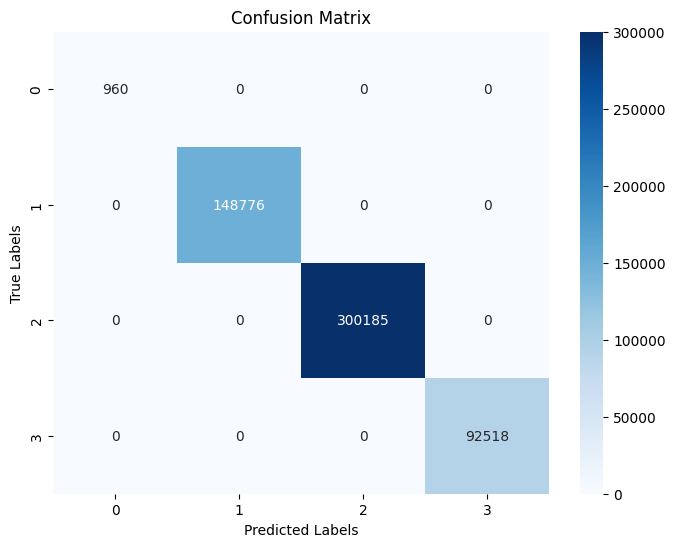

In [10]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/firstinitialized/felids_RNN_cate.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/category/client1_FELIDS_rnn_cate_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [11]:
print(f"Accuracy for 4 class classification felids_rnn_cate_bfore fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_rnn_cate_bfore  fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_rnn_cate_bfore  fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_rnn_cate_bfore  fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_rnn_cate_bfore  fl: {mcc:.4f}")

Accuracy for 4 class classification felids_rnn_cate_bfore fl: 1.0000
Precision for 4 class classification felids_rnn_cate_bfore  fl: 1.0000
Recall for 4 class classification felids_rnn_cate_bfore  fl: 1.0000
F1 Score for 4 class classification felids_rnn_cate_bfore  fl: 1.0000
MCC for 4 class classification felids_rnn_cate_bfore  fl: 1.0000


Felids rnn type before fl classification

31643/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.9602 - loss: 0.0974
Epoch 1: val_loss improved from inf to 0.00175, saving model to D:/linthoi/FL_models/new/client1/type/client1_FELIDS_rnn_type_bfore_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 2109s 67ms/step - accuracy: 0.9602 - loss: 0.0974 - val_accuracy: 0.9996 - val_loss: 0.0017
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 319s 19ms/step
Accuracy Score: 0.999670008977968


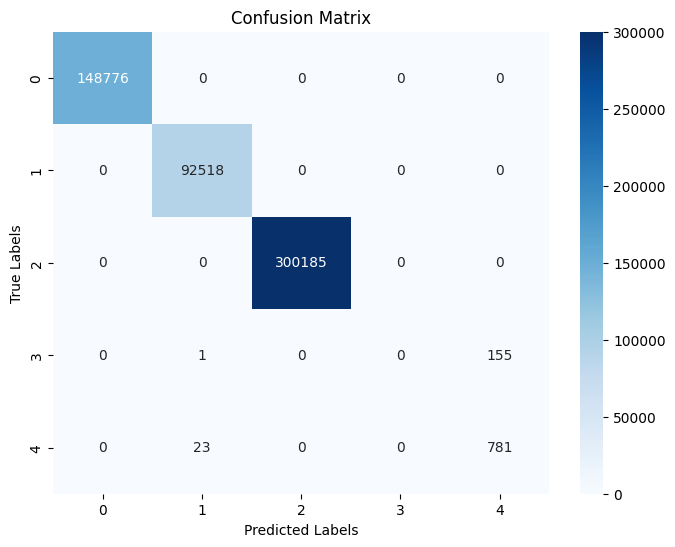

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [5]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/firstinitialized/felids_RNN_type.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_FELIDS_rnn_type_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [6]:
print(f"Accuracy for 5 class classification felids_rnn_type_bfore fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_rnn_type_bfore  fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_rnn_type_bfore  fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_rnn_type_bfore  fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_rnn_type_bfore  fl: {mcc:.4f}")

Accuracy for 5 class classification felids_rnn_type_bfore fl: 0.9997
Precision for 5 class classification felids_rnn_type_bfore  fl: 0.7668
Recall for 5 class classification felids_rnn_type_bfore  fl: 0.7943
F1 Score for 5 class classification felids_rnn_type_bfore  fl: 0.7795
MCC for 5 class classification felids_rnn_type_bfore  fl: 0.9994


1st fl round felids rnn type classification

31643/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.9872 - loss: 0.0464
Epoch 1: val_loss improved from inf to 0.00084, saving model to D:/linthoi/FL_models/new/client1/type/client1_FELIDS_rnn_type_1st_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 2108s 66ms/step - accuracy: 0.9872 - loss: 0.0464 - val_accuracy: 0.9997 - val_loss: 8.3966e-04
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 323s 19ms/step
Accuracy Score: 0.9997124100590112


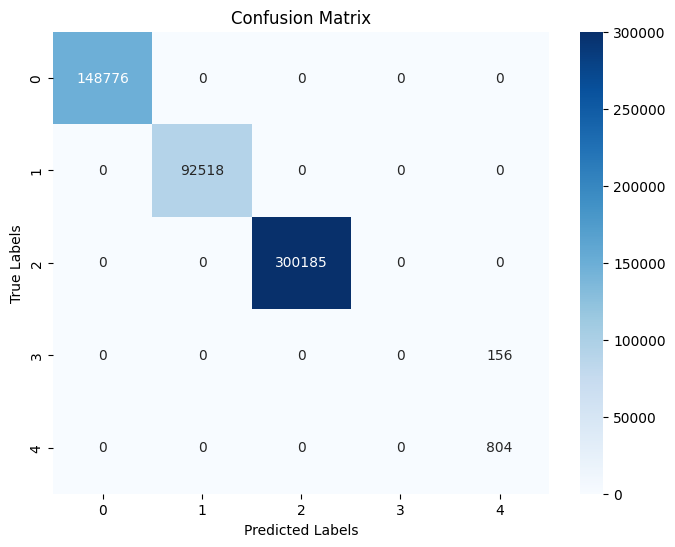

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [4]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/1st_round_felids_rnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_FELIDS_rnn_type_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [5]:
print(f"Accuracy for 5 class classification felids_rnn_type_1st fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_rnn_type_1st  fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_rnn_type_1st  fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_rnn_type_1st  fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_rnn_type_1st  fl: {mcc:.4f}")

Accuracy for 5 class classification felids_rnn_type_1st fl: 0.9997
Precision for 5 class classification felids_rnn_type_1st  fl: 0.7675
Recall for 5 class classification felids_rnn_type_1st  fl: 0.8000
F1 Score for 5 class classification felids_rnn_type_1st  fl: 0.7823
MCC for 5 class classification felids_rnn_type_1st  fl: 0.9995


felids rnn type 2nd fl round

31643/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.9937 - loss: 0.0221
Epoch 1: val_loss improved from inf to 0.00085, saving model to D:/linthoi/FL_models/new/client1/type/client1_FELIDS_rnn_type_2nd_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 2408s 76ms/step - accuracy: 0.9937 - loss: 0.0221 - val_accuracy: 0.9997 - val_loss: 8.4958e-04
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 345s 20ms/step
Accuracy Score: 0.9997124100590112


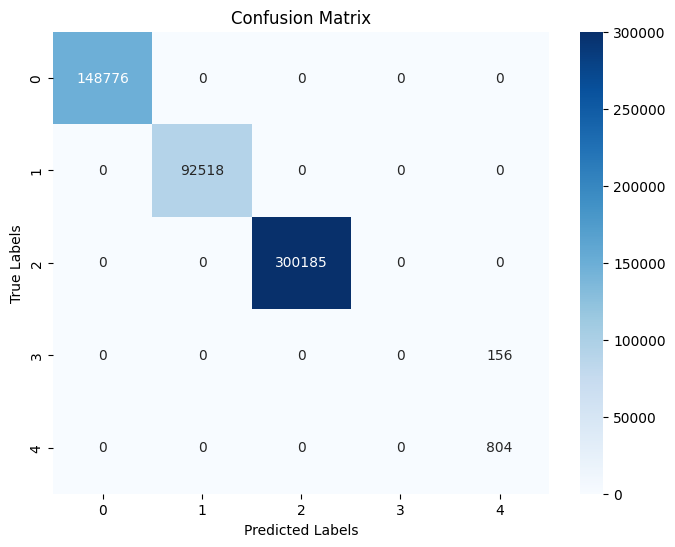

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/2nd_round_felids_rnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_FELIDS_rnn_type_2nd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 5 class classification felids_rnn_type_2nd fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_rnn_type_2nd  fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_rnn_type_2nd  fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_rnn_type_2nd  fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_rnn_type_2nd  fl: {mcc:.4f}")

Accuracy for 5 class classification felids_rnn_type_2nd fl: 0.9997
Precision for 5 class classification felids_rnn_type_2nd  fl: 0.7675
Recall for 5 class classification felids_rnn_type_2nd  fl: 0.8000
F1 Score for 5 class classification felids_rnn_type_2nd  fl: 0.7823
MCC for 5 class classification felids_rnn_type_2nd  fl: 0.9995


2nd fl felids rnn type classification round

31643/31643 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.9968 - loss: 0.0122
Epoch 1: val_loss improved from inf to 0.00082, saving model to D:/linthoi/FL_models/new/client1/type/client1_FELIDS_rnn_type_3rd_FL_weight.keras
31643/31643 ━━━━━━━━━━━━━━━━━━━━ 2227s 70ms/step - accuracy: 0.9968 - loss: 0.0122 - val_accuracy: 0.9997 - val_loss: 8.2381e-04
Restoring model weights from the end of the best epoch: 1.
16952/16952 ━━━━━━━━━━━━━━━━━━━━ 330s 19ms/step
Accuracy Score: 0.9997124100590112


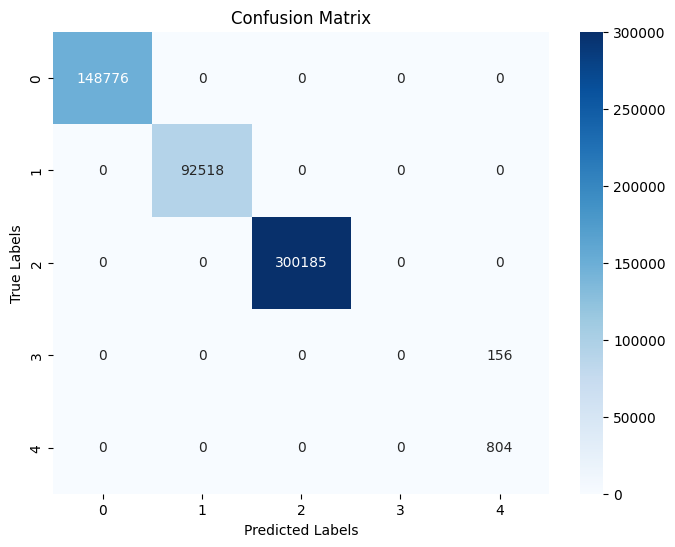

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [4]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/3rd_round_felids_rnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/type/client1_FELIDS_rnn_type_3rd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [5]:
print(f"Accuracy for 5 class classification felids_rnn_type_3rd fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_rnn_type_3rd  fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_rnn_type_3rd  fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_rnn_type_3rd  fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_rnn_type_3rd  fl: {mcc:.4f}")

Accuracy for 5 class classification felids_rnn_type_3rd fl: 0.9997
Precision for 5 class classification felids_rnn_type_3rd  fl: 0.7675
Recall for 5 class classification felids_rnn_type_3rd  fl: 0.8000
F1 Score for 5 class classification felids_rnn_type_3rd  fl: 0.7823
MCC for 5 class classification felids_rnn_type_3rd  fl: 0.9995
